**Data PreProcessing, Training and Analysis**

1. Import Libraries

In [1]:
#importing machine learning libraries

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from math import erf, sqrt
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

2. Import Dataset

In [2]:
# Load dataset
df = pd.read_csv("Brdrisk_with_scores.csv")


3. Data Leakage Prevention, Variables Definition, PreProcessing, Train_Test Split

In [3]:
# Drop all engineered scores and prevalence column
columns_to_drop = [
    "AgeScore", "WeightScore", "TransportDistanceScore", "TransitTimeScore",
    "AmbientTempScore", "ArrivalTempScore", "DustScore", "HumidityScore",
    "SeasonScore", "GeneticResilienceScore", "SexScore", "NutritionScore",
    "ImmuneStatusScore", "PreviousHealthScore", "CominglingScore",
    "PreconditioningScore", "RecentWeaningScore", "BRDPathogenScore",
    "VaccinatedScore", "LateCastrationScore", "HousingTypeScore", "BreedScore",
    "TemperamentScore", "BrdRiskIndex", "BRDRisk"
]

# Drop the columns
X = df.drop(columns=columns_to_drop + ["BRDRisk"])  # Exclude the target variable as well
y = df["BRDRisk"].astype('category').cat.codes

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(exclude=['number']).columns.tolist()

# Preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown='ignore', drop="first"))
])

# Combine transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ])

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)


4. Initial Model Training and Evaluation

In [4]:
# Define a function to evaluate the model
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba)
    
    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    }

# Initialize a dictionary to store the results
results = {}

# 1. Logistic Regression
logreg_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("clf", LogisticRegression(max_iter=500))
])
logreg_pipeline.fit(X_train, y_train)
results["Logistic Regression"] = evaluate_model(logreg_pipeline, X_test, y_test)

# 2. Random Forest
rf_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("clf", RandomForestClassifier(n_estimators=200, random_state=42))
])
rf_pipeline.fit(X_train, y_train)
results["Random Forest"] = evaluate_model(rf_pipeline, X_test, y_test)

# 3. Support Vector Machine
svc_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("clf", SVC(probability=True))
])
svc_pipeline.fit(X_train, y_train)
results["SVC"] = evaluate_model(svc_pipeline, X_test, y_test)

# 4. K-Nearest Neighbors
knn_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("clf", KNeighborsClassifier())
])
knn_pipeline.fit(X_train, y_train)
results["K-Nearest Neighbors"] = evaluate_model(knn_pipeline, X_test, y_test)

# 5. XGBoost
xgb_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("clf", XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42))
])
xgb_pipeline.fit(X_train, y_train)
results["XGBoost"] = evaluate_model(xgb_pipeline, X_test, y_test)

c:\Users\adeolu.adekunle\.conda\envs\Adeolujoe\Lib\site-packages\xgboost\core.py:158: UserWarning: [14:36:07] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


In [5]:
# Display results in a smart tabular format
results_data = []
for model_name, metrics in results.items():
    results_data.append([
        model_name,
        metrics["Accuracy"],
        metrics["Precision"],
        metrics["Recall"],
        metrics["F1 Score"],
        metrics["ROC-AUC"]
    ])
# Round numeric values in each model row before creating the DataFrame
results_data = [
    [
        model_name,
        round(metrics["Accuracy"], 3),
        round(metrics["Precision"], 3),
        round(metrics["Recall"], 3),
        round(metrics["F1 Score"], 3),
        round(metrics["ROC-AUC"], 3),
    ]
    for model_name, metrics in results.items()
]
results_table = pd.DataFrame(results_data, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"])
print(results_table.to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression     0.925      0.838   0.773     0.804    0.972
      Random Forest     0.873      0.958   0.380     0.544    0.955
                SVC     0.939      0.870   0.817     0.843    0.979
K-Nearest Neighbors     0.870      0.723   0.567     0.636    0.884
            XGBoost     0.938      0.909   0.768     0.833    0.984


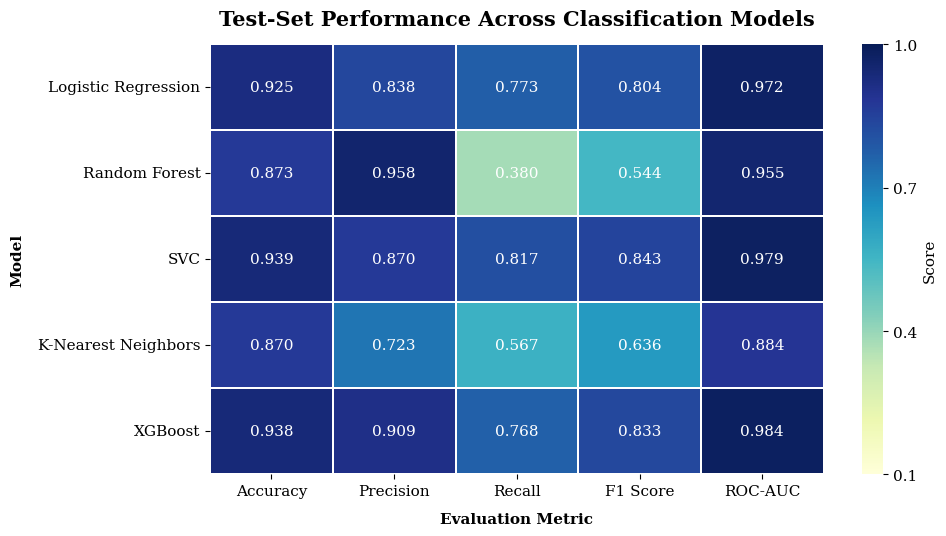

In [6]:
performance_df = pd.DataFrame(results).T[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
]

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titleweight": "bold"
})

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.heatmap(
    np.round(performance_df, 3),
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    vmin=0.1,
    vmax=1.0,
    linewidths=1.2,
    linecolor="white",
    cbar_kws={"label": "Score", "ticks": np.linspace(0.1, 1.0, 4)},
    annot_kws={"color": "white", "fontsize": 11},
    ax=ax
)

ax.set_title("Test-Set Performance Across Classification Models", pad=14, fontsize=15)
ax.set_xlabel("Evaluation Metric", weight="bold", labelpad=10)
ax.set_ylabel("Model", labelpad=10, weight="bold")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()
fig.savefig("model_performance_heatmap.pdf", bbox_inches="tight")
fig.savefig("model_performance_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

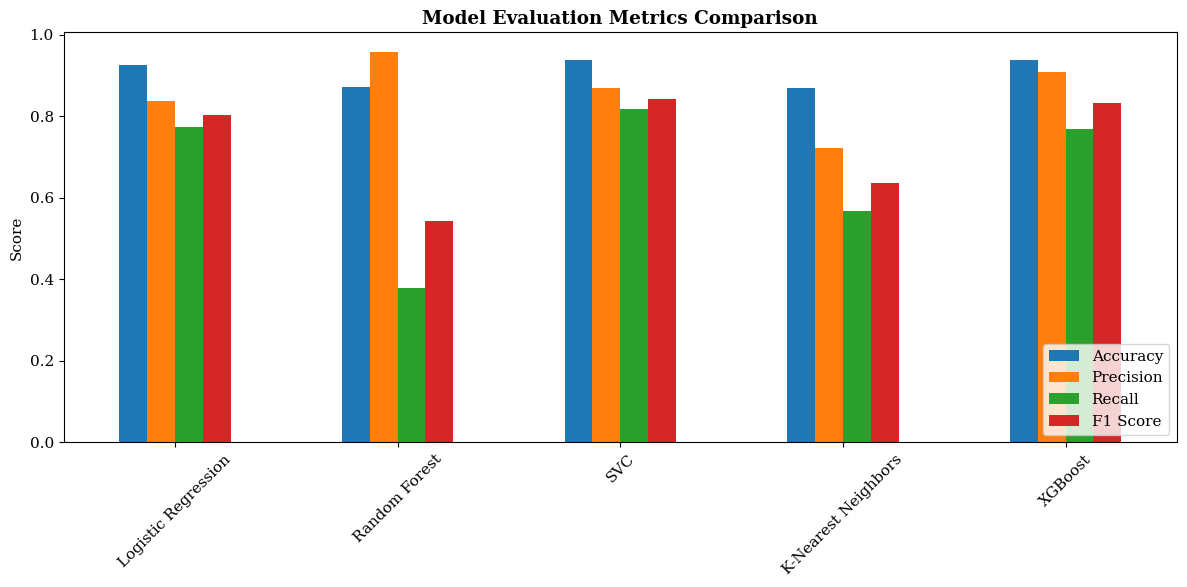

In [7]:
# Plot comparison

results_df = pd.DataFrame(results).T
results_df.drop(columns=["ROC-AUC"], errors='ignore').plot(kind="bar", figsize=(12, 6))
plt.title("Model Evaluation Metrics Comparison")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [8]:
# Compare the models based on a chosen metric (e.g., Accuracy)
best_model = max(results, key=lambda model: results[model]["Accuracy"])
print(f"The best model based on Accuracy is: {best_model}")

# Print the evaluation metrics for the best model
print("\nBest Model Evaluation Metrics:")
for metric, value in results[best_model].items():
    print(f"  {metric}: {value:.4f}" if isinstance(value, float) else f"  {metric}: {value}")

The best model based on Accuracy is: SVC

Best Model Evaluation Metrics:
  Accuracy: 0.9390
  Precision: 0.8703
  Recall: 0.8167
  F1 Score: 0.8426
  ROC-AUC: 0.9793


In [9]:
# Tabular confusion matrices for all models
models = {
    "Logistic Regression": logreg_pipeline,
    "Random Forest": rf_pipeline,
    "SVC": svc_pipeline,
    "K-Nearest Neighbors": knn_pipeline,
    "XGBoost": xgb_pipeline
}

cm_rows = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    total = tn + fp + fn + tp
    cm_rows.append({
        "Model": name,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "Accuracy": (tn + tp) / total,
        "Precision": tp / (tp + fp) if (tp + fp) > 0 else 0.0,
        "Recall": tp / (tp + fn) if (tp + fn) > 0 else 0.0
    })

cm_df = pd.DataFrame(cm_rows).set_index("Model")
cm_df

,TN,FP,FN,TP,Accuracy,Precision,Recall
Model,,,,,,,
Logistic Regression,2310,90,136,464,0.924667,0.837545,0.773333
Random Forest,2390,10,372,228,0.872667,0.957983,0.380000
SVC,2327,73,110,490,0.939000,0.870337,0.816667
K-Nearest Neighbors,2270,130,260,340,0.870000,0.723404,0.566667
XGBoost,2354,46,139,461,0.938333,0.909270,0.768333


5. Initial Model Cross-Validation

In [10]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from math import erf, sqrt
from sklearn.model_selection import cross_validate, cross_val_predict, StratifiedKFold

def _normal_cdf(x):
    return (1 + erf(x / sqrt(2))) / 2

def _compute_midrank(x):
    x = np.asarray(x, dtype=np.float64)
    sorted_idx = np.argsort(x)
    sorted_x = x[sorted_idx]
    midranks = np.empty(len(x), dtype=np.float64)

    i = 0
    while i < len(x):
        j = i
        while j + 1 < len(x) and sorted_x[j] == sorted_x[j + 1]:
            j += 1
        midrank = 0.5 * (i + j) + 1
        midranks[i:j + 1] = midrank
        i = j + 1

    inv_sorted_idx = np.empty(len(x), dtype=np.int64)
    inv_sorted_idx[sorted_idx] = np.arange(len(x))
    return midranks[inv_sorted_idx]

def _fast_delong(predictions, label_1_count):
    predictions = np.asarray(predictions, dtype=np.float64)
    n_models, n_samples = predictions.shape
    m = int(label_1_count)
    n = n_samples - m

    tx = np.zeros((n_models, m), dtype=np.float64)
    ty = np.zeros((n_models, n), dtype=np.float64)
    tz = np.zeros((n_models, n_samples), dtype=np.float64)

    for r in range(n_models):
        tz[r] = _compute_midrank(predictions[r])
        tx[r] = _compute_midrank(predictions[r, :m])
        ty[r] = _compute_midrank(predictions[r, m:])

    aucs = (np.sum(tz[:, :m], axis=1) - m * (m + 1) / 2) / (m * n)
    v01 = (tz[:, :m] - tx) / n
    v10 = (tz[:, m:] - ty) / m

    sx = np.cov(v01, rowvar=True, bias=True)
    sy = np.cov(v10, rowvar=True, bias=True)

    return aucs, sx / m + sy / n

def delong_roc_test(y_true, prob_a, prob_b):
    y_true = np.asarray(y_true)
    pos_idx = np.where(y_true == 1)[0]
    neg_idx = np.where(y_true == 0)[0]
    order = np.concatenate([pos_idx, neg_idx])

    predictions = np.vstack([prob_a, prob_b])[:, order]
    aucs, cov = _fast_delong(predictions, len(pos_idx))

    diff = aucs[0] - aucs[1]
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]

    if var <= 0:
        p_value = np.nan
    else:
        z = diff / np.sqrt(var)
        p_value = 2 * (1 - _normal_cdf(abs(z)))

    return aucs, p_value

cv_models = {
    "Logistic Regression": logreg_pipeline,
    "Random Forest": rf_pipeline,
    "SVC": svc_pipeline,
    "K-Nearest Neighbors": knn_pipeline,
    "XGBoost": xgb_pipeline,
}

cv_skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cv_scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_statistics = {}
cv_auc_folds = {}
cv_oof_probas = {}

for model_name, model in cv_models.items():
    cv_results = cross_validate(
        model,
        X,
        y,
        cv=cv_skf,
        scoring=cv_scoring,
        return_train_score=False,
        n_jobs=-1
    )

    cv_statistics[model_name] = {
        metric: (cv_results[f"test_{metric}"].mean(), cv_results[f"test_{metric}"].std())
        for metric in cv_scoring
    }
    cv_auc_folds[model_name] = cv_results["test_roc_auc"]

    cv_oof_probas[model_name] = cross_val_predict(
        model,
        X,
        y,
        cv=cv_skf,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

cv_summary_df = pd.DataFrame({
    model_name: {
        metric: f"{mean:.4f} ± {std:.4f}"
        for metric, (mean, std) in metrics.items()
    }
    for model_name, metrics in cv_statistics.items()
}).T

print("Stratified 10-Fold Cross-Validation Results (mean ± std):")
cv_summary_df

pairwise_results = []
model_names = list(cv_models.keys())

for i in range(len(model_names)):
    for j in range(i + 1, len(model_names)):
        name_a = model_names[i]
        name_b = model_names[j]

        aucs, p_value = delong_roc_test(
            y,
            cv_oof_probas[name_a],
            cv_oof_probas[name_b]
        )

        pairwise_results.append({
            "Model A": name_a,
            "Model B": name_b,
            "AUC A": aucs[0],
            "AUC B": aucs[1],
            "AUC Difference": aucs[0] - aucs[1],
            "p-value": p_value,
            "Significant (α=0.05)": p_value < 0.05 if not np.isnan(p_value) else False
        })

pairwise_comparison_df = pd.DataFrame(pairwise_results)
print("\nPairwise Comparison of Cross-Validated AUCs using Correlated ROC Curve Test:")
pairwise_comparison_df

Stratified 10-Fold Cross-Validation Results (mean ± std):

Pairwise Comparison of Cross-Validated AUCs using Correlated ROC Curve Test:


,Model A,Model B,AUC A,AUC B,AUC Difference,p-value,Significant (α=0.05)
0,Logistic Regression,Random Forest,0.967438,0.950965,0.016473,4.440892e-16,True
1,Logistic Regression,SVC,0.967438,0.978724,-0.011286,0.000000e+00,True
2,Logistic Regression,K-Nearest Neighbors,0.967438,0.886343,0.081095,0.000000e+00,True
3,Logistic Regression,XGBoost,0.967438,0.983190,-0.015752,0.000000e+00,True
4,Random Forest,SVC,0.950965,0.978724,-0.027759,0.000000e+00,True
5,Random Forest,K-Nearest Neighbors,0.950965,0.886343,0.064623,0.000000e+00,True
6,Random Forest,XGBoost,0.950965,0.983190,-0.032225,0.000000e+00,True
7,SVC,K-Nearest Neighbors,0.978724,0.886343,0.092381,0.000000e+00,True
8,SVC,XGBoost,0.978724,0.983190,-0.004466,2.054361e-05,True
9,K-Nearest Neighbors,XGBoost,0.886343,0.983190,-0.096847,0.000000e+00,True


6. Complete, Development and Holdout Data Distribution

In [11]:
datasets = {
    "Complete": X,
    "Development": X_train,
    "Holdout": X_test
}

def _is_binary_predictor(series):
    values = set(series.dropna().unique())
    return (
        pd.api.types.is_bool_dtype(series)
        or (
            pd.api.types.is_numeric_dtype(series)
            and values.issubset({0, 1, False, True})
        )
    )

rows = []

for feature in X.columns:
    series_full = X[feature]
    is_numeric = pd.api.types.is_numeric_dtype(series_full)
    is_binary = _is_binary_predictor(series_full)

    if is_numeric and not is_binary:
        row = {
            "Predictor": feature,
            "Type": "Continuous",
            "Category": ""
        }

        for dataset_name, data in datasets.items():
            values = pd.to_numeric(data[feature], errors="coerce").dropna()
            if values.empty:
                row[dataset_name] = "No data"
            else:
                q1, median, q3 = values.quantile([0.25, 0.50, 0.75])
                row[dataset_name] = (
                    f"Mean ± SD: {values.mean():.2f} ± {values.std():.2f}; "
                    f"Median [Q1, Q3]: {median:.2f} [{q1:.2f}, {q3:.2f}]"
                )

        rows.append(row)

    else:
        predictor_type = "Binary" if is_binary else "Categorical"
        categories = list(series_full.dropna().unique())
        categories.sort(key=str)

        # Include missing values as an explicit category when present.
        if series_full.isna().any():
            categories.append("<Missing>")

        for category in categories:
            row = {
                "Predictor": feature,
                "Type": predictor_type,
                "Category": str(category)
            }

            for dataset_name, data in datasets.items():
                values = data[feature]
                if category == "<Missing>":
                    count = int(values.isna().sum())
                else:
                    count = int(values.eq(category).fillna(False).sum())

                percent = 100 * count / len(values) if len(values) else 0
                row[dataset_name] = f"{count} ({percent:.1f}%)"

            rows.append(row)

distribution_table = pd.DataFrame(rows)
distribution_table.to_csv("predictor_distribution_table.csv", index=False)
print(distribution_table.to_string(index=False))

            Predictor        Type   Category                                                             Complete                                                          Development                                                              Holdout
                  age  Continuous                    Mean ± SD: 10.00 ± 1.92; Median [Q1, Q3]: 9.99 [8.65, 11.34]        Mean ± SD: 10.01 ± 1.93; Median [Q1, Q3]: 10.01 [8.67, 11.34]          Mean ± SD: 9.97 ± 1.92; Median [Q1, Q3]: 9.95 [8.62, 11.34]
               weight  Continuous             Mean ± SD: 504.24 ± 94.06; Median [Q1, Q3]: 501.58 [433.80, 569.39]  Mean ± SD: 504.45 ± 94.05; Median [Q1, Q3]: 501.78 [434.33, 569.53]  Mean ± SD: 503.74 ± 94.10; Median [Q1, Q3]: 501.05 [433.11, 568.69]
   transport_distance  Continuous            Mean ± SD: 498.25 ± 196.38; Median [Q1, Q3]: 498.85 [359.97, 632.78] Mean ± SD: 497.56 ± 197.27; Median [Q1, Q3]: 499.63 [359.81, 632.46] Mean ± SD: 499.84 ± 194.32; Median [Q1, Q3]: 497.00 [360.13, 

7. Hyperparameter Optimization

In [12]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define hyperparameter grids for each model
param_grids = {
    "Logistic Regression": {
        "clf__C": [0.001, 0.01, 0.1, 1, 10, 100],
        "clf__solver": ["lbfgs", "liblinear"],
        "clf__max_iter": [500, 1000]
    },
    "Random Forest": {
        "clf__n_estimators": [100, 200, 300],
        "clf__max_depth": [10, 20, 30, None],
        "clf__min_samples_split": [2, 5, 10],
        "clf__min_samples_leaf": [1, 2, 4]
    },
    "SVC": {
        "clf__C": [0.1, 1, 10, 100],
        "clf__kernel": ["rbf"],
        "clf__gamma": ["scale", "auto"]
    },
    "K-Nearest Neighbors": {
        "clf__n_neighbors": [3, 5, 7, 9, 11],
        "clf__weights": ["uniform", "distance"],
        "clf__metric": ["euclidean", "manhattan"]
    },
    "XGBoost": {
        "clf__n_estimators": [100, 200, 300],
        "clf__max_depth": [3, 5, 7],
        "clf__learning_rate": [0.01, 0.1, 0.2],
        "clf__subsample": [0.8, 0.9, 1.0],
        "clf__colsample_bytree": [0.8, 0.9, 1.0]
    }
}

# Initialize StratifiedKFold for cross-validation
skf_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Dictionary to store optimized models
optimized_models = {}

# Grid Search for each model
for model_name in ["Logistic Regression", "Random Forest", "SVC", "K-Nearest Neighbors", "XGBoost"]:
    print(f"\nPerforming Grid Search for {model_name}...")
    
    # Get the base pipeline
    if model_name == "Logistic Regression":
        base_pipeline = logreg_pipeline
    elif model_name == "Random Forest":
        base_pipeline = rf_pipeline
    elif model_name == "SVC":
        base_pipeline = svc_pipeline
    elif model_name == "K-Nearest Neighbors":
        base_pipeline = knn_pipeline
    else:  # XGBoost
        base_pipeline = xgb_pipeline
    
    # Perform GridSearchCV
    grid_search = GridSearchCV(
        estimator=base_pipeline,
        param_grid=param_grids[model_name],
        cv=skf_cv,
        scoring="roc_auc",
        n_jobs=-1,
            verbose=1
        )
    
    grid_search.fit(X_train, y_train)
    
    # Store results
    optimized_models[model_name] = {
        "best_params": grid_search.best_params_,
        "best_score": grid_search.best_score_,
        "best_estimator": grid_search.best_estimator_
    }
    
    print(f"{model_name} - Best ROC-AUC Score: {grid_search.best_score_:.4f}")
    print(f"Best Parameters: {grid_search.best_params_}")

# Retrain optimized models on full training set and evaluate on test set
optimized_results = {}

for model_name, opt_model_info in optimized_models.items():
    best_estimator = opt_model_info["best_estimator"]
    
    # Retrain on full training set
    best_estimator.fit(X_train, y_train)
    
    # Evaluate on test set
    optimized_results[model_name] = evaluate_model(best_estimator, X_test, y_test)
    
    print(f"\n{model_name} - Optimized Test Set Performance:")
    for metric, value in optimized_results[model_name].items():
        print(f"  {metric}: {value:.4f}")

# Compare original vs optimized results
print("\n" + "="*80)
print("Comparison: Original vs Optimized Models")
print("="*80)

comparison_data = []
for model_name in results.keys():
    comparison_data.append({
        "Model": model_name,
        "Original Accuracy": results[model_name]["Accuracy"],
        "Optimized Accuracy": optimized_results[model_name]["Accuracy"],
        "Original ROC-AUC": results[model_name]["ROC-AUC"],
        "Optimized ROC-AUC": optimized_results[model_name]["ROC-AUC"]
    })

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))


Performing Grid Search for Logistic Regression...
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Logistic Regression - Best ROC-AUC Score: 0.9646
Best Parameters: {'clf__C': 1, 'clf__max_iter': 500, 'clf__solver': 'liblinear'}

Performing Grid Search for Random Forest...
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Random Forest - Best ROC-AUC Score: 0.9479
Best Parameters: {'clf__max_depth': 30, 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 2, 'clf__n_estimators': 300}

Performing Grid Search for SVC...
Fitting 5 folds for each of 8 candidates, totalling 40 fits
SVC - Best ROC-AUC Score: 0.9746
Best Parameters: {'clf__C': 1, 'clf__gamma': 'auto', 'clf__kernel': 'rbf'}

Performing Grid Search for K-Nearest Neighbors...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
K-Nearest Neighbors - Best ROC-AUC Score: 0.9152
Best Parameters: {'clf__metric': 'manhattan', 'clf__n_neighbors': 11, 'clf__weights': 'distance'}

Performing Grid Sea

c:\Users\adeolu.adekunle\.conda\envs\Adeolujoe\Lib\site-packages\xgboost\core.py:158: UserWarning: [14:47:41] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBoost - Best ROC-AUC Score: 0.9908
Best Parameters: {'clf__colsample_bytree': 1.0, 'clf__learning_rate': 0.2, 'clf__max_depth': 3, 'clf__n_estimators': 300, 'clf__subsample': 0.8}

Logistic Regression - Optimized Test Set Performance:
  Accuracy: 0.9247
  Precision: 0.8375
  Recall: 0.7733
  F1 Score: 0.8042
  ROC-AUC: 0.9721

Random Forest - Optimized Test Set Performance:
  Accuracy: 0.8720
  Precision: 0.9696
  Recall: 0.3717
  F1 Score: 0.5373
  ROC-AUC: 0.9558

SVC - Optimized Test Set Performance:
  Accuracy: 0.9373
  Precision: 0.8692
  Recall: 0.8083
  F1 Score: 0.8377
  ROC-AUC: 0.9799

K-Nearest Neighbors - Optimized Test Set Performance:
  Accuracy: 0.8897
  Precision: 0.8289
  Recall: 0.5650
  F1 Score: 0.6720
  ROC-AUC: 0.9211


c:\Users\adeolu.adekunle\.conda\envs\Adeolujoe\Lib\site-packages\xgboost\core.py:158: UserWarning: [14:48:05] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



XGBoost - Optimized Test Set Performance:
  Accuracy: 0.9623
  Precision: 0.9419
  Recall: 0.8650
  F1 Score: 0.9018
  ROC-AUC: 0.9924

Comparison: Original vs Optimized Models
              Model  Original Accuracy  Optimized Accuracy  Original ROC-AUC  Optimized ROC-AUC
Logistic Regression           0.924667            0.924667          0.972128           0.972124
      Random Forest           0.872667            0.872000          0.955291           0.955823
                SVC           0.939000            0.937333          0.979308           0.979865
K-Nearest Neighbors           0.870000            0.889667          0.884414           0.921078
            XGBoost           0.938333            0.962333          0.983688           0.992415


In [13]:
perf_df = pd.DataFrame(optimized_results).T[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
]
perf_df.index.name = "Model"
perf_df.index.name = "Model"

metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#B279A2"]

fig = go.Figure()

for i, metric in enumerate(metrics):
    fig.add_trace(
        go.Bar(
            x=perf_df.index,
            y=perf_df[metric].values,
            name=metric,
            marker=dict(color=colors[i], line=dict(color="black", width=1)),
            text=[f"{v:.3f}" for v in perf_df[metric].values],
            textposition="outside",
            hovertemplate=f"{metric}<br>Model: %{{x}}<br>Score: %{{y:.3f}}<extra></extra>"
        )
    )

fig.update_layout(
    barmode="group",
    title=dict(
        text="Optimized Test Set Performance by Model",
        x=0.5,
        font=dict(family="Times New Roman", size=16, color="black")
    ),
    xaxis=dict(
        title=dict(text="Model", font=dict(family="Times New Roman", size=14)),
        tickangle=0,
        showgrid=False,
        tickfont=dict(family="Times New Roman", size=14)
    ),
    yaxis=dict(
        title=dict(text="Score", font=dict(family="Times New Roman", size=14)),
        range=[0, 1.03],
        tickformat=".2f",
        showgrid=True,
        gridcolor="lightgray",
        tickfont=dict(family="Times New Roman", size=14)
    ),
    legend=dict(
        title=dict(text="Metric", font=dict(family="Times New Roman", size=14)),
        orientation="h",
        x=0.5,
        xanchor="center",
        y=1.10,
        yanchor="bottom",
        font=dict(family="Times New Roman", size=14)
    ),
    font=dict(family="Times New Roman", size=14, color="black"),
    template="plotly_white",
    width=1400,
    height=800,
    margin=dict(l=80, r=80, t=90, b=120),
    paper_bgcolor="white",
    plot_bgcolor="white",
    bargap=0.15,
    bargroupgap=0.15,
    uniformtext_minsize=14,
    uniformtext_mode="hide"
)

fig.show()

8. Nested Cross Validation - Optimized Model

In [14]:
# Nested cross-validation: inner loop tunes hyperparameters;
# outer loop estimates performance on data not used for tuning.

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

base_pipelines = {
    "Logistic Regression": logreg_pipeline,
    "Random Forest": rf_pipeline,
    "SVC": svc_pipeline,
    "K-Nearest Neighbors": knn_pipeline,
    "XGBoost": xgb_pipeline
}

y_array = np.asarray(y).astype(int)
nested_results = {}
nested_fold_rows = []
nested_best_params = {}

for model_name, base_pipeline in base_pipelines.items():
    print(f"Nested cross-validation: {model_name}")

    oof_probabilities = np.full(len(y_array), np.nan)
    oof_predictions = np.full(len(y_array), -1, dtype=int)
    best_params_by_fold = []

    for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y_array), start=1):
        X_outer_train = X.iloc[train_idx]
        X_outer_test = X.iloc[test_idx]
        y_outer_train = y_array[train_idx]
        y_outer_test = y_array[test_idx]

        search = GridSearchCV(
            estimator=base_pipeline,
            param_grid=param_grids[model_name],
            scoring="roc_auc",
            cv=inner_cv,
            n_jobs=-1,
            refit=True,
            error_score="raise"
        )
        search.fit(X_outer_train, y_outer_train)

        best_model = search.best_estimator_
        fold_probabilities = best_model.predict_proba(X_outer_test)[:, 1]
        fold_predictions = best_model.predict(X_outer_test)

        oof_probabilities[test_idx] = fold_probabilities
        oof_predictions[test_idx] = fold_predictions
        best_params_by_fold.append(search.best_params_)

        nested_fold_rows.append({
            "Model": model_name,
            "Outer Fold": fold,
            "Inner Best ROC-AUC": search.best_score_,
            "Outer ROC-AUC": roc_auc_score(y_outer_test, fold_probabilities),
            "Outer Accuracy": accuracy_score(y_outer_test, fold_predictions),
            "Outer Precision": precision_score(
                y_outer_test, fold_predictions, zero_division=0
            ),
            "Outer Recall": recall_score(
                y_outer_test, fold_predictions, zero_division=0
            ),
            "Outer F1": f1_score(
                y_outer_test, fold_predictions, zero_division=0
            )
        })

    # Pooled out-of-fold predictions: each observation was held out from tuning and fitting.
    nested_results[model_name] = {
        "Accuracy": accuracy_score(y_array, oof_predictions),
        "Precision": precision_score(y_array, oof_predictions, zero_division=0),
        "Recall": recall_score(y_array, oof_predictions, zero_division=0),
        "F1": f1_score(y_array, oof_predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_array, oof_probabilities)
    }
    nested_best_params[model_name] = best_params_by_fold

nested_fold_df = pd.DataFrame(nested_fold_rows)
nested_summary_df = pd.DataFrame(nested_results).T
nested_summary_df.index.name = "Model"

print("\nPooled outer-fold performance for the tuned workflows:")
display(nested_summary_df.round(4))

print("\nOuter-fold metric means and standard deviations:")
nested_fold_summary = (
    nested_fold_df
    .groupby("Model")[[
        "Outer ROC-AUC", "Outer Accuracy", "Outer Precision",
        "Outer Recall", "Outer F1"
    ]]
    .agg(["mean", "std"])
)
display(nested_fold_summary.round(4))

print("\nBest inner-loop parameters for each outer fold:")
for model_name, fold_params in nested_best_params.items():
    print(f"\n{model_name}")
    for fold, params in enumerate(fold_params, start=1):
        print(f"  Fold {fold}: {params}")

Nested cross-validation: Logistic Regression
Nested cross-validation: Random Forest
Nested cross-validation: SVC
Nested cross-validation: K-Nearest Neighbors
Nested cross-validation: XGBoost


c:\Users\adeolu.adekunle\.conda\envs\Adeolujoe\Lib\site-packages\xgboost\core.py:158: UserWarning:

[15:49:48] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.


c:\Users\adeolu.adekunle\.conda\envs\Adeolujoe\Lib\site-packages\xgboost\core.py:158: UserWarning:

[15:55:08] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.


c:\Users\adeolu.adekunle\.conda\envs\Adeolujoe\Lib\site-packages\xgboost\core.py:158: UserWarning:

[15:58:41] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.


c:\Users\adeolu.adekunle\.conda\envs\Adeolujoe\Lib\site-packages\xgboost\cor


Pooled outer-fold performance for the tuned workflows:


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.9189,0.8177,0.7650,0.7905,0.9676
Random Forest,0.8740,0.9602,0.3860,0.5506,0.9520
SVC,0.9360,0.8786,0.7890,0.8314,0.9787
K-Nearest Neighbors,0.8843,0.8162,0.5440,0.6529,0.9228
XGBoost,0.9573,0.9348,0.8455,0.8879,0.9917



Outer-fold metric means and standard deviations:


Outer ROC-AUC         Outer Accuracy          \
                             mean     std           mean     std   
Model                                                              
K-Nearest Neighbors        0.9226  0.0114         0.8843  0.0075   
Logistic Regression        0.9677  0.0017         0.9189  0.0016   
Random Forest              0.9520  0.0054         0.8740  0.0022   
SVC                        0.9787  0.0020         0.9360  0.0051   
XGBoost                    0.9917  0.0010         0.9573  0.0020   

                    Outer Precision         Outer Recall         Outer F1  \
                               mean     std         mean     std     mean   
Model                                                                       
K-Nearest Neighbors          0.8167  0.0314       0.5440  0.0215   0.6528   
Logistic Regression          0.8179  0.0084       0.7650  0.0164   0.7904   
Random Forest                0.9611  0.0241       0.3860  0.0145   0.5505   
SVC                          0.8788  0.0159       0.7890  0.0197   0.8313   
XGBoost                      0.9348  0.0073       0.8455  0.0099   0.8879   

                             
                        std  
Model                        
K-Nearest Neighbors  0.0224  
Logistic Regression  0.0063  
Random Forest        0.0126  
SVC                  0.0139  
XGBoost              0.0055


Best inner-loop parameters for each outer fold:

Logistic Regression
  Fold 1: {'clf__C': 100, 'clf__max_iter': 500, 'clf__solver': 'liblinear'}
  Fold 2: {'clf__C': 10, 'clf__max_iter': 500, 'clf__solver': 'liblinear'}
  Fold 3: {'clf__C': 100, 'clf__max_iter': 500, 'clf__solver': 'lbfgs'}
  Fold 4: {'clf__C': 10, 'clf__max_iter': 500, 'clf__solver': 'liblinear'}
  Fold 5: {'clf__C': 100, 'clf__max_iter': 500, 'clf__solver': 'lbfgs'}

Random Forest
  Fold 1: {'clf__max_depth': 30, 'clf__min_samples_leaf': 4, 'clf__min_samples_split': 2, 'clf__n_estimators': 300}
  Fold 2: {'clf__max_depth': 20, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 5, 'clf__n_estimators': 300}
  Fold 3: {'clf__max_depth': 20, 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 5, 'clf__n_estimators': 300}
  Fold 4: {'clf__max_depth': 30, 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 5, 'clf__n_estimators': 300}
  Fold 5: {'clf__max_depth': 20, 'clf__min_samples_leaf': 1, 'clf__min_samples_sp

Confusion Matrix_Optimized

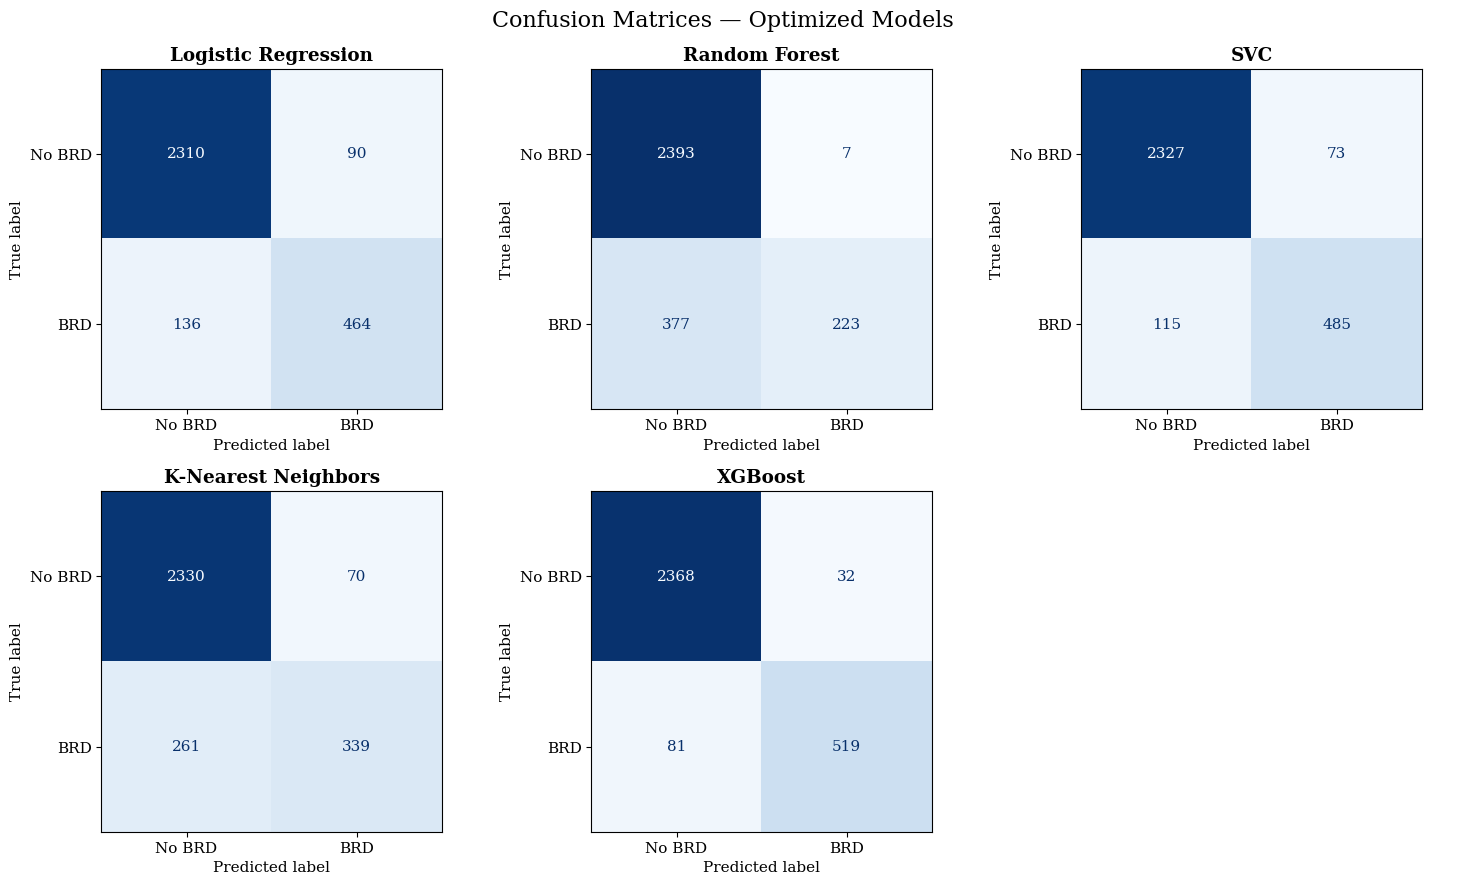

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

# Plot confusion matrices for the five optimized estimators
model_names = list(optimized_models.keys())
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

# Use a shared color scale so matrices are comparable
confusion_matrices = {
    name: confusion_matrix(
        y_test,
        model_info["best_estimator"].predict(X_test),
        labels=[0, 1]
    )
    for name, model_info in optimized_models.items()
}
vmax = max(cm.max() for cm in confusion_matrices.values())

for ax, (model_name, cm) in zip(axes, confusion_matrices.items()):
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No BRD", "BRD"]
    )
    display.plot(
        ax=ax,
        cmap=plt.cm.Blues,
        values_format="d",
        colorbar=False,
        im_kw={"vmin": 0, "vmax": vmax}
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

for ax in axes[len(model_names):]:
    ax.axis("off")

fig.suptitle("Confusion Matrices — Optimized Models", fontsize=16)
fig.tight_layout()
plt.show()

ROC_AUC Curves

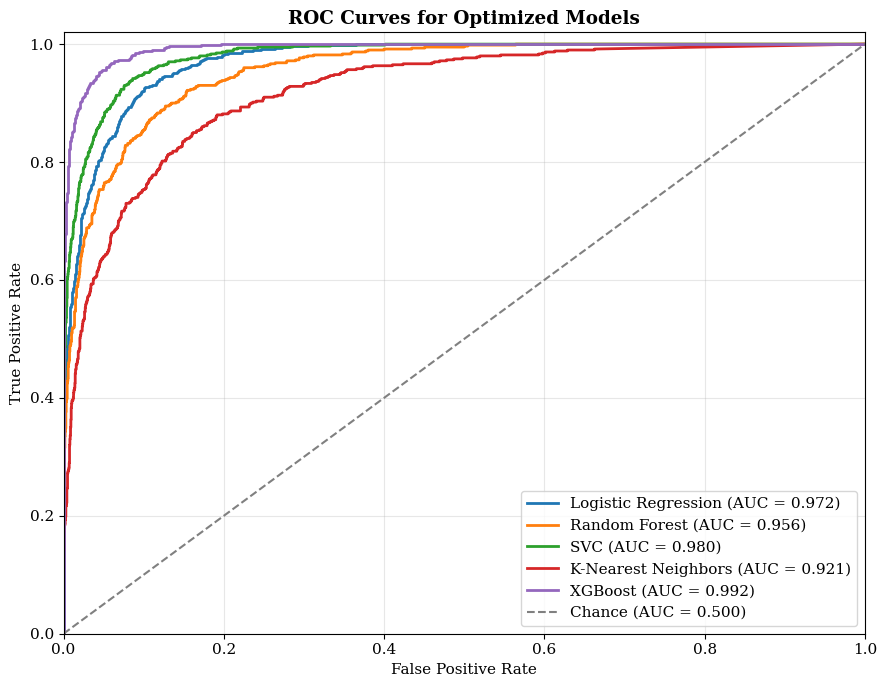

In [17]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(9, 7))

for model_name, model_info in optimized_models.items():
    estimator = model_info["best_estimator"]
    positive_class_index = np.where(estimator.classes_ == 1)[0][0]
    y_score = estimator.predict_proba(X_test)[:, positive_class_index]

    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc_value = roc_auc_score(y_test, y_score)

    plt.plot(fpr, tpr, linewidth=2, label=f"{model_name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Optimized Models")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

PR Curves

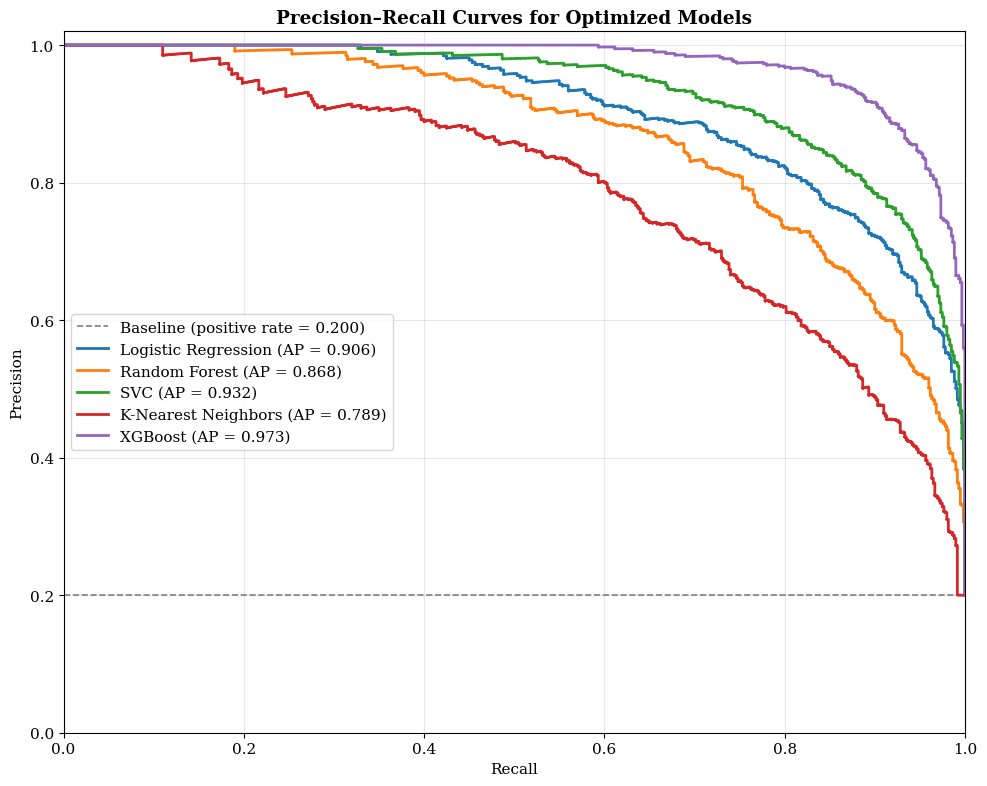

In [20]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Precision–Recall curves for the optimized estimators
plt.figure(figsize=(10, 8))

baseline = np.asarray(y_test).mean()
plt.axhline(
    baseline,
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label=f"Baseline (positive rate = {baseline:.3f})"
)

for model_name, model_info in optimized_models.items():
    estimator = model_info["best_estimator"]
    y_proba = estimator.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    ap_score = average_precision_score(y_test, y_proba)

    plt.step(
        recall,
        precision,
        where="post",
        linewidth=2,
        label=f"{model_name} (AP = {ap_score:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves for Optimized Models")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

Brier Scores

Brier Scores (Optimized Models):
Logistic Regression: 0.0529
Random Forest: 0.0865
SVC: 0.0441
K-Nearest Neighbors: 0.0888
XGBoost: 0.0295


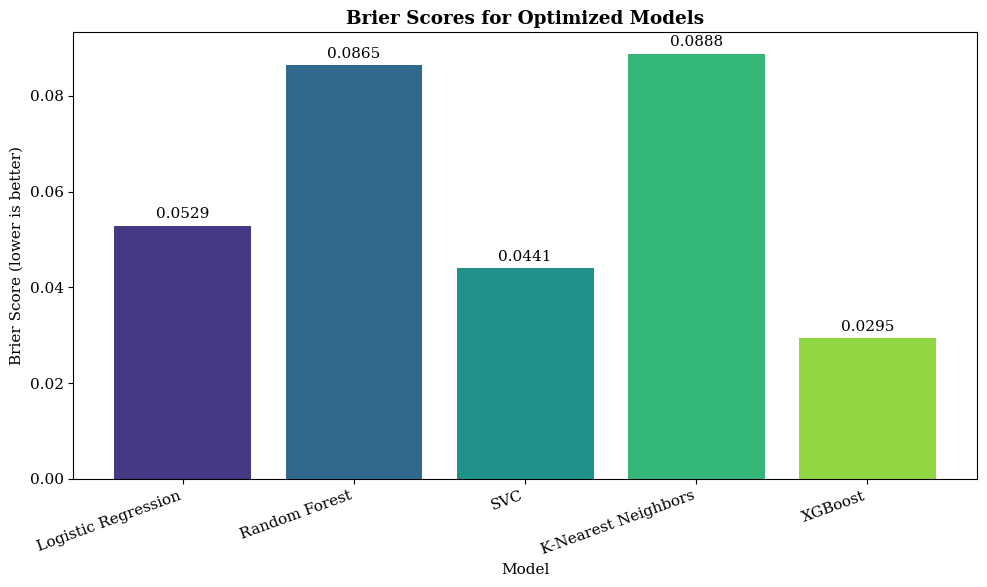

In [22]:
from sklearn.metrics import brier_score_loss
optimized_brier_scores = {}

for model_name, model_info in optimized_models.items():
    estimator = model_info["best_estimator"]
    y_proba = estimator.predict_proba(X_test)[:, 1]
    optimized_brier_scores[model_name] = brier_score_loss(y_test, y_proba)

print("Brier Scores (Optimized Models):")
for model_name, score in optimized_brier_scores.items():
    print(f"{model_name}: {score:.4f}")

plt.figure(figsize=(10, 6))
bars = plt.bar(
    optimized_brier_scores.keys(),
    optimized_brier_scores.values(),
    color=sns.color_palette("viridis", n_colors=len(optimized_brier_scores))
)
plt.bar_label(bars, fmt="%.4f", padding=3)
plt.xlabel("Model")
plt.ylabel("Brier Score (lower is better)")
plt.title("Brier Scores for Optimized Models")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

Calibration Curves

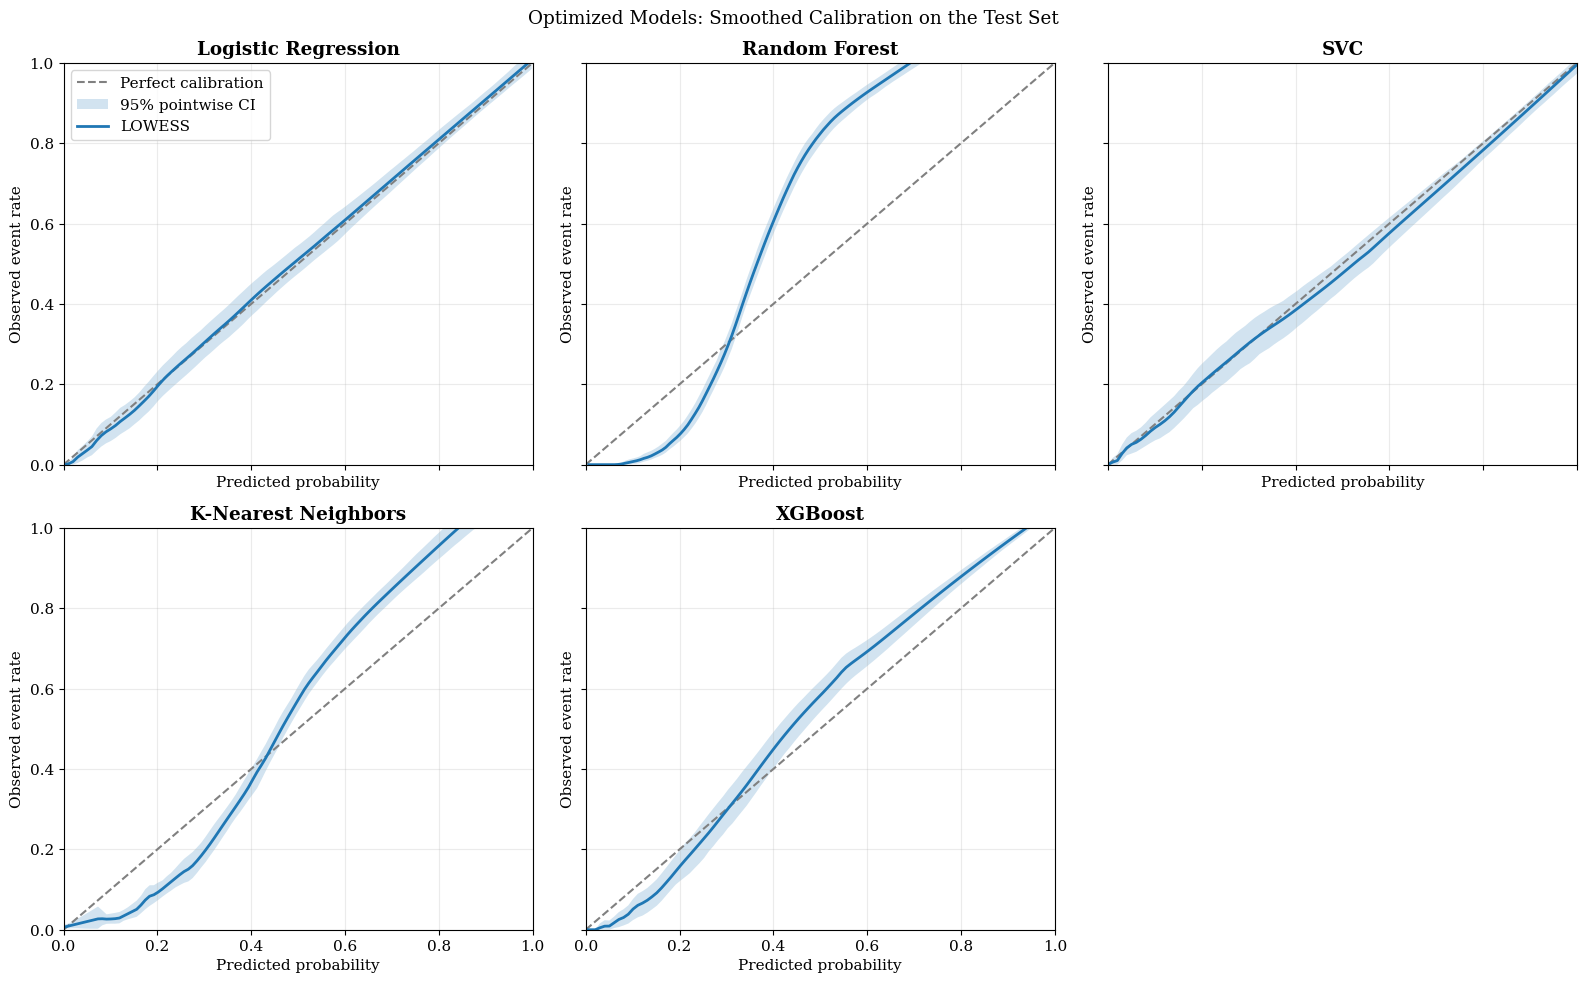

              Model  Calibration-in-the-large      CITL 95% CI  Calibration slope   Slope 95% CI
Logistic Regression                 -0.029083  [-0.179, 0.120]           1.129578 [1.024, 1.235]
      Random Forest                 -0.052983  [-0.152, 0.047]           3.299191 [3.007, 3.591]
                SVC                 -0.108070  [-0.280, 0.064]           1.005840 [0.910, 1.102]
K-Nearest Neighbors                 -0.191724 [-0.298, -0.086]           1.475635 [1.341, 1.611]
            XGBoost                  0.151953  [-0.015, 0.319]           1.724380 [1.521, 1.928]


In [23]:
from scipy.special import logit
from statsmodels.nonparametric.smoothers_lowess import lowess

import statsmodels.api as sm

# Evaluate optimized estimators on the held-out test set.
y_cal = np.asarray(y_test).astype(int)
rng_cal = np.random.default_rng(42)
n_boot_cal = 500
n_calibration_points = 100
lowess_frac = 0.30
eps = 1e-6

positive_idx = np.flatnonzero(y_cal == 1)
negative_idx = np.flatnonzero(y_cal == 0)
if len(positive_idx) == 0 or len(negative_idx) == 0:
    raise ValueError("The test set must contain both outcome classes.")

calibration_rows = []
calibration_probabilities = {}

fig, axes = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey=True)
axes = axes.ravel()

for ax, (model_name, model_info) in zip(axes, optimized_models.items()):
    estimator = model_info["best_estimator"]
    prob = estimator.predict_proba(X_test)[:, 1]
    prob = np.clip(prob, eps, 1 - eps)
    calibration_probabilities[model_name] = prob
    logit_prob = logit(prob)

    # Calibration-in-the-large: estimate an intercept with the prediction
    # log-odds held fixed as an offset.
    cil_fit = sm.GLM(
        y_cal,
        np.ones((len(y_cal), 1)),
        family=sm.families.Binomial(),
        offset=logit_prob
    ).fit()
    cil, cil_ci = cil_fit.params[0], cil_fit.conf_int()[0]

    # Calibration slope: fit outcome on prediction log-odds with an intercept.
    slope_fit = sm.GLM(
        y_cal,
        sm.add_constant(logit_prob),
        family=sm.families.Binomial()
    ).fit()
    slope, slope_ci = slope_fit.params[1], slope_fit.conf_int()[1]

    calibration_rows.append({
        "Model": model_name,
        "Calibration-in-the-large": cil,
        "CITL 95% CI": f"[{cil_ci[0]:.3f}, {cil_ci[1]:.3f}]",
        "Calibration slope": slope,
        "Slope 95% CI": f"[{slope_ci[0]:.3f}, {slope_ci[1]:.3f}]"
    })

    # LOWESS-smoothed observed outcome versus predicted probability.
    x_grid = np.linspace(
        np.quantile(prob, 0.01),
        np.quantile(prob, 0.99),
        n_calibration_points
    )
    smooth = lowess(y_cal, prob, frac=lowess_frac, it=0, return_sorted=True)
    smooth_y = np.interp(x_grid, smooth[:, 0], smooth[:, 1])

    # Stratified bootstrap preserves the observed counts of both classes.
    bootstrap_curves = []
    for _ in range(n_boot_cal):
        sample_idx = np.concatenate([
            rng_cal.choice(positive_idx, size=len(positive_idx), replace=True),
            rng_cal.choice(negative_idx, size=len(negative_idx), replace=True)
        ])
        boot_smooth = lowess(
            y_cal[sample_idx], prob[sample_idx],
            frac=lowess_frac, it=0, return_sorted=True
        )
        bootstrap_curves.append(
            np.interp(x_grid, boot_smooth[:, 0], boot_smooth[:, 1])
        )

    ci_low, ci_high = np.quantile(bootstrap_curves, [0.025, 0.975], axis=0)

    ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
    ax.fill_between(x_grid, ci_low, ci_high, alpha=0.2, label="95% pointwise CI")
    ax.plot(x_grid, smooth_y, color="C0", linewidth=2, label="LOWESS")
    ax.set_title(model_name)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Predicted probability")
    ax.set_ylabel("Observed event rate")
    ax.grid(alpha=0.25)

for ax in axes[len(optimized_models):]:
    ax.axis("off")

axes[0].legend(loc="best")
fig.suptitle("Optimized Models: Smoothed Calibration on the Test Set")
fig.tight_layout()
plt.show()

calibration_summary_df = pd.DataFrame(calibration_rows)
print(calibration_summary_df.to_string(index=False))

9. 95% Confidence Interval BootStrap Estimates

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)

n_bootstrap = 2000
decision_threshold = 0.5
n_calibration_bins = 10
bootstrap_rng = np.random.default_rng(42)

bootstrap_y = np.asarray(y_test).astype(int)
positive_idx = np.flatnonzero(bootstrap_y == 1)
negative_idx = np.flatnonzero(bootstrap_y == 0)

if len(positive_idx) == 0 or len(negative_idx) == 0:
    raise ValueError("The test set must contain both outcome classes.")

def _bootstrap_ece(y_true, y_prob, n_bins=10):
    bin_ids = np.minimum((y_prob * n_bins).astype(int), n_bins - 1)
    return sum(
        (mask := (bin_ids == bin_id)).mean()
        * abs(y_true[mask].mean() - y_prob[mask].mean())
        for bin_id in range(n_bins)
        if (mask := (bin_ids == bin_id)).any()
    )

def _bootstrap_metrics(y_true, y_prob):
    y_pred = (y_prob >= decision_threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    return {
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC (average precision)": average_precision_score(y_true, y_prob),
        "Sensitivity / Recall": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Brier score": brier_score_loss(y_true, y_prob),
        "ECE": _bootstrap_ece(y_true, y_prob, n_calibration_bins)
    }

bootstrap_rows = []

for model_name, model_info in optimized_models.items():
    estimator = model_info["best_estimator"]
    positive_class_idx = np.flatnonzero(estimator.classes_ == 1)[0]
    test_prob = estimator.predict_proba(X_test)[:, positive_class_idx]

    point_metrics = _bootstrap_metrics(bootstrap_y, test_prob)
    bootstrap_values = {metric: [] for metric in point_metrics}

    for _ in range(n_bootstrap):
        sampled_idx = np.concatenate([
            bootstrap_rng.choice(positive_idx, size=len(positive_idx), replace=True),
            bootstrap_rng.choice(negative_idx, size=len(negative_idx), replace=True)
        ])
        replicate = _bootstrap_metrics(
            bootstrap_y[sampled_idx],
            test_prob[sampled_idx]
        )
        for metric, value in replicate.items():
            bootstrap_values[metric].append(value)

    for metric, estimate in point_metrics.items():
        ci_low, ci_high = np.nanquantile(
            bootstrap_values[metric], [0.025, 0.975]
        )
        bootstrap_rows.append({
            "Model": model_name,
            "Metric": metric,
            "Estimate": estimate,
            "95% CI": f"[{ci_low:.4f}, {ci_high:.4f}]"
        })

bootstrap_ci_df = pd.DataFrame(bootstrap_rows)
print(bootstrap_ci_df.to_string(index=False))

              Model                     Metric  Estimate           95% CI
Logistic Regression                    ROC-AUC  0.972124 [0.9666, 0.9767]
Logistic Regression PR-AUC (average precision)  0.905712 [0.8887, 0.9208]
Logistic Regression       Sensitivity / Recall  0.773333 [0.7400, 0.8050]
Logistic Regression                Specificity  0.962500 [0.9542, 0.9700]
Logistic Regression                  Precision  0.837545 [0.8076, 0.8654]
Logistic Regression                         F1  0.804159 [0.7795, 0.8271]
Logistic Regression                Brier score  0.052907 [0.0484, 0.0581]
Logistic Regression                        ECE  0.010235 [0.0096, 0.0212]
      Random Forest                    ROC-AUC  0.955823 [0.9481, 0.9632]
      Random Forest PR-AUC (average precision)  0.867912 [0.8463, 0.8881]
      Random Forest       Sensitivity / Recall  0.371667 [0.3350, 0.4133]
      Random Forest                Specificity  0.997083 [0.9950, 0.9992]
      Random Forest                  P

10. Threshold Sensitivity Analysis

              Model  Threshold  Accuracy  Precision   Recall  F1 Score
Logistic Regression        0.1  0.853000   0.578635 0.975000  0.726257
Logistic Regression        0.2  0.893333   0.666667 0.933333  0.777778
Logistic Regression        0.3  0.915000   0.739251 0.888333  0.806964
Logistic Regression        0.4  0.923333   0.795527 0.830000  0.812398
Logistic Regression        0.5  0.924667   0.837545 0.773333  0.804159
Logistic Regression        0.6  0.922667   0.875510 0.715000  0.787156
Logistic Regression        0.7  0.912667   0.904306 0.630000  0.742633
      Random Forest        0.1  0.552333   0.308604 0.998333  0.471468
      Random Forest        0.2  0.785000   0.481328 0.966667  0.642659
      Random Forest        0.3  0.893667   0.691678 0.845000  0.760690
      Random Forest        0.4  0.910000   0.876712 0.640000  0.739884
      Random Forest        0.5  0.872000   0.969565 0.371667  0.537349
      Random Forest        0.6  0.845000   0.992701 0.226667  0.369064
      

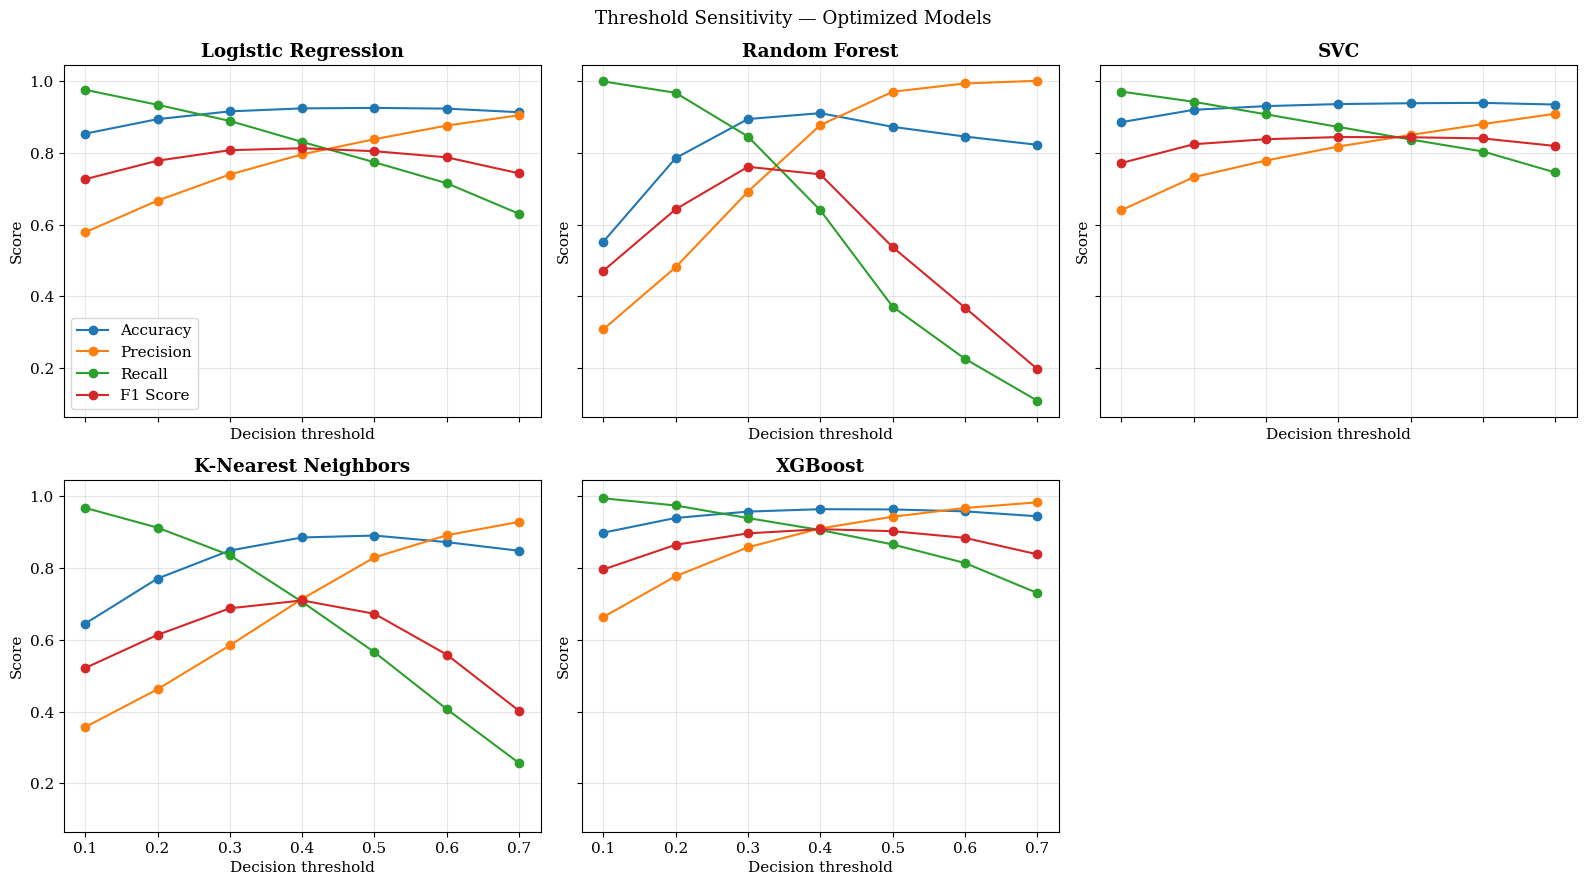

In [25]:
# Threshold sensitivity for each optimized estimator on the held-out test set.
# Sensitivity analysis for classification threshold on optimized models
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

threshold_sensitivity_rows = []
y_test_threshold = np.asarray(y_test).astype(int)

for model_name, model_info in optimized_models.items():
    estimator = model_info["best_estimator"]
    positive_class_idx = np.flatnonzero(estimator.classes_ == 1)[0]
    probabilities = estimator.predict_proba(X_test)[:, positive_class_idx]

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)
        threshold_sensitivity_rows.append({
            "Model": model_name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_test_threshold, predictions),
            "Precision": precision_score(y_test_threshold, predictions, zero_division=0),
            "Recall": recall_score(y_test_threshold, predictions, zero_division=0),
            "F1 Score": f1_score(y_test_threshold, predictions, zero_division=0)
        })

optimized_threshold_df = pd.DataFrame(threshold_sensitivity_rows)
print(optimized_threshold_df.to_string(index=False))

# Plot metrics separately for each optimized model.
model_order = list(optimized_models.keys())
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)
axes = axes.ravel()

metric_names = ["Accuracy", "Precision", "Recall", "F1 Score"]

for ax, model_name in zip(axes, model_order):
    model_data = optimized_threshold_df[
        optimized_threshold_df["Model"] == model_name
    ]

    for metric in metric_names:
        ax.plot(
            model_data["Threshold"],
            model_data[metric],
            marker="o",
            label=metric
        )

    ax.set_title(model_name)
    ax.set_xlabel("Decision threshold")
    ax.set_ylabel("Score")
    ax.set_xticks(thresholds)
    ax.grid(alpha=0.3)

for ax in axes[len(model_order):]:
    ax.axis("off")

axes[0].legend(loc="best")
fig.suptitle("Threshold Sensitivity — Optimized Models")
fig.tight_layout()
plt.show()

11. Permutation importance - Top 5 Features

              Model  Rank               Feature  Importance_Mean  Importance_Std
Logistic Regression     1 brd_pathogen_positive         0.085915        0.003946
Logistic Regression     2       preconditioning         0.047515        0.002555
Logistic Regression     3       previous_health         0.031127        0.001021
Logistic Regression     4    genetic_resilience         0.030986        0.001179
Logistic Regression     5         immune_status         0.029127        0.002715
      Random Forest     1 brd_pathogen_positive         0.124227        0.005518
      Random Forest     2       preconditioning         0.056508        0.003185
      Random Forest     3    genetic_resilience         0.036930        0.001327
      Random Forest     4       previous_health         0.032083        0.001126
      Random Forest     5             nutrition         0.031729        0.002559
                SVC     1 brd_pathogen_positive         0.087744        0.003694
                SVC     2   

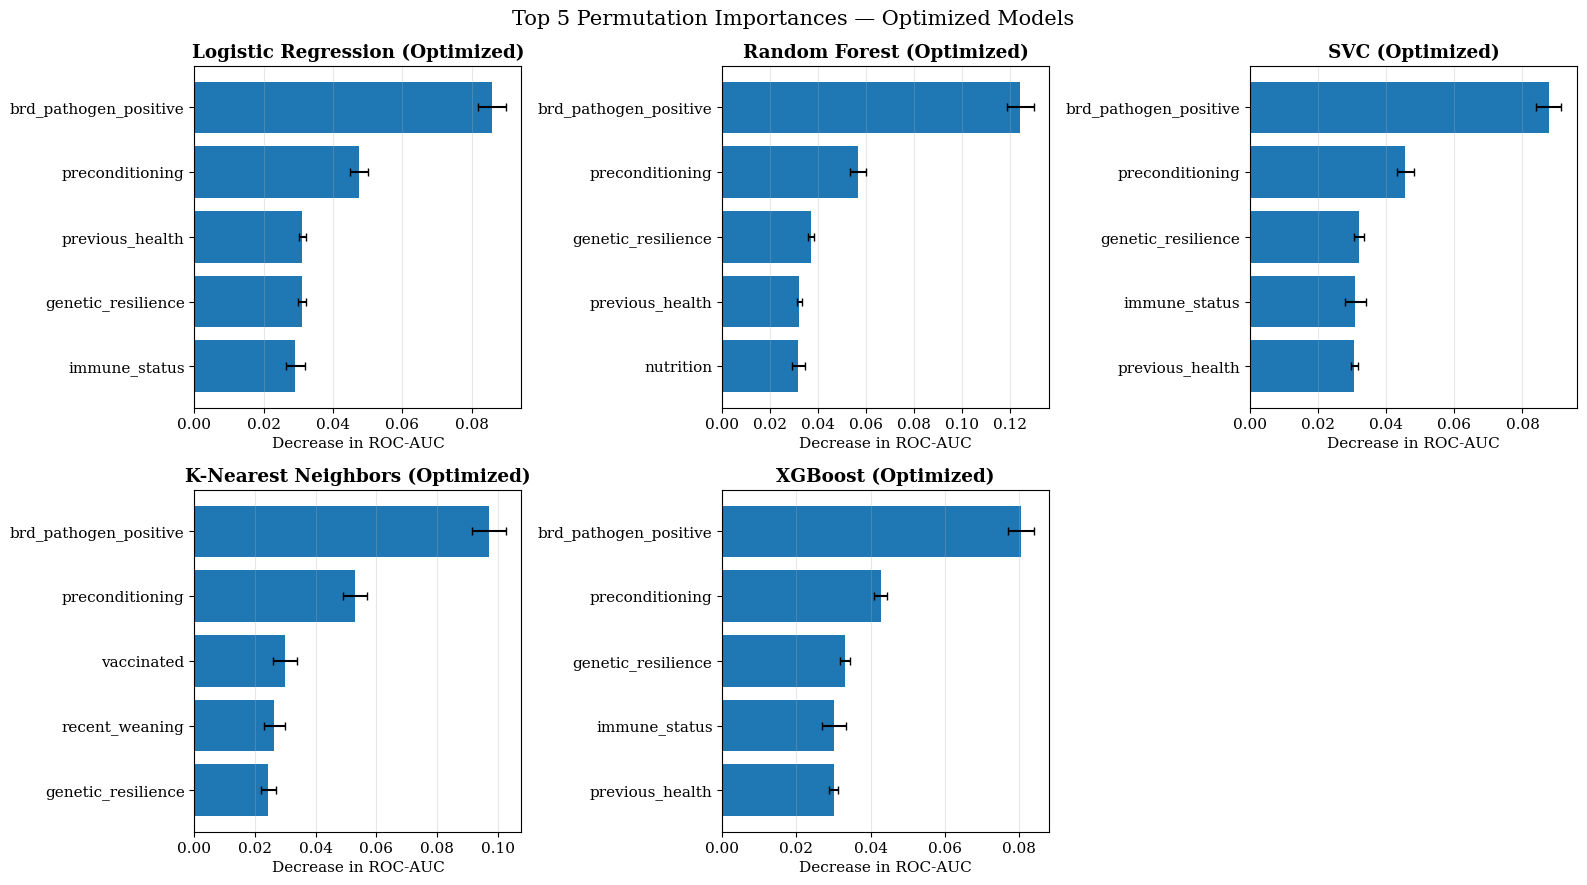

In [26]:
from sklearn.inspection import permutation_importance

top_n = 5
optimized_permutation_rows = []

for model_name, model_info in optimized_models.items():
    fitted_model = model_info["best_estimator"]

    perm_result = permutation_importance(
        fitted_model,
        X_test,
        y_test,
        scoring="roc_auc",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    importance_df = pd.DataFrame({
        "Feature": X_test.columns,
        "Importance_Mean": perm_result.importances_mean,
        "Importance_Std": perm_result.importances_std
    }).sort_values("Importance_Mean", ascending=False)

    for rank, row in enumerate(importance_df.head(top_n).itertuples(index=False), start=1):
        optimized_permutation_rows.append({
            "Model": model_name,
            "Rank": rank,
            "Feature": row.Feature,
            "Importance_Mean": row.Importance_Mean,
            "Importance_Std": row.Importance_Std
        })

optimized_top_permutation_df = pd.DataFrame(optimized_permutation_rows)
print(optimized_top_permutation_df.to_string(index=False))

# Plot the top features for each optimized model
model_order = list(optimized_models.keys())
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, model_name in enumerate(model_order):
    plot_data = (
        optimized_top_permutation_df[
            optimized_top_permutation_df["Model"] == model_name
        ]
        .sort_values("Importance_Mean", ascending=True)
    )

    axes[idx].barh(
        plot_data["Feature"],
        plot_data["Importance_Mean"],
        xerr=plot_data["Importance_Std"],
        capsize=3
    )
    axes[idx].set_title(f"{model_name} (Optimized)")
    axes[idx].set_xlabel("Decrease in ROC-AUC")
    axes[idx].grid(axis="x", alpha=0.3)

for ax in axes[len(model_order):]:
    ax.axis("off")

fig.suptitle(f"Top {top_n} Permutation Importances — Optimized Models", fontsize=15)
fig.tight_layout()
plt.show()

12. SHAP Explainer Analysis

PermutationExplainer explainer: 101it [00:16,  6.08it/s]                         


SHAP summary: Logistic Regression (optimized)


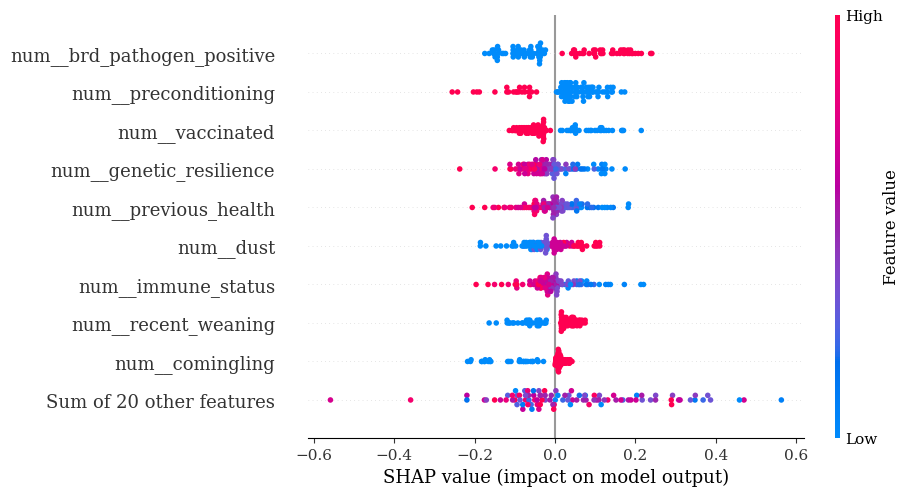

PermutationExplainer explainer: 101it [00:14,  1.61it/s]                         


SHAP summary: Random Forest (optimized)


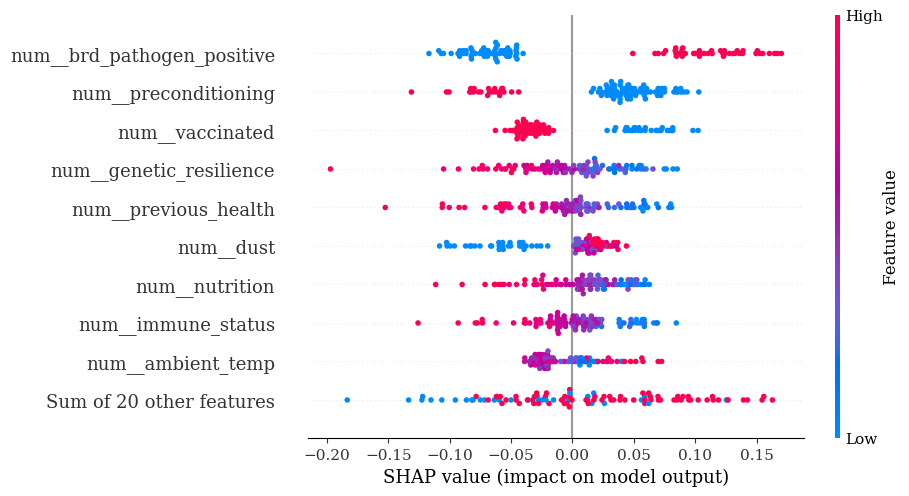

PermutationExplainer explainer: 101it [02:12,  1.47s/it]                         


SHAP summary: SVC (optimized)


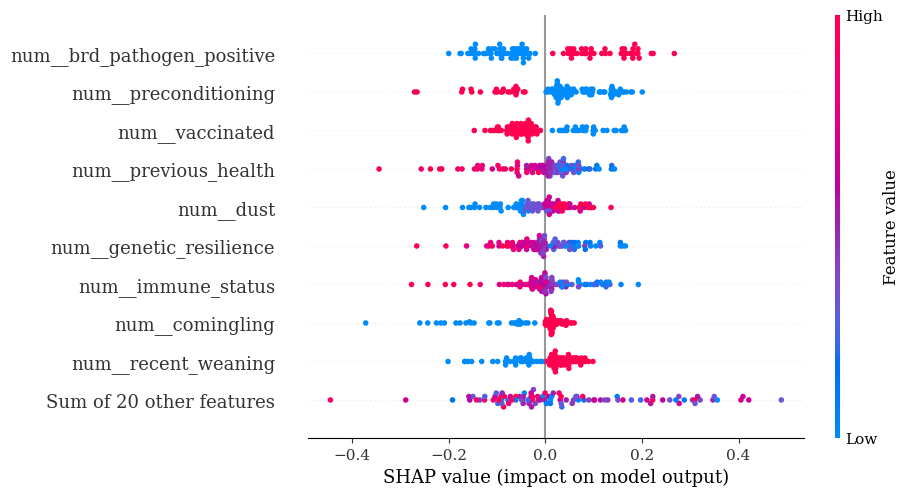

PermutationExplainer explainer: 101it [03:01,  2.09s/it]                         


SHAP summary: K-Nearest Neighbors (optimized)


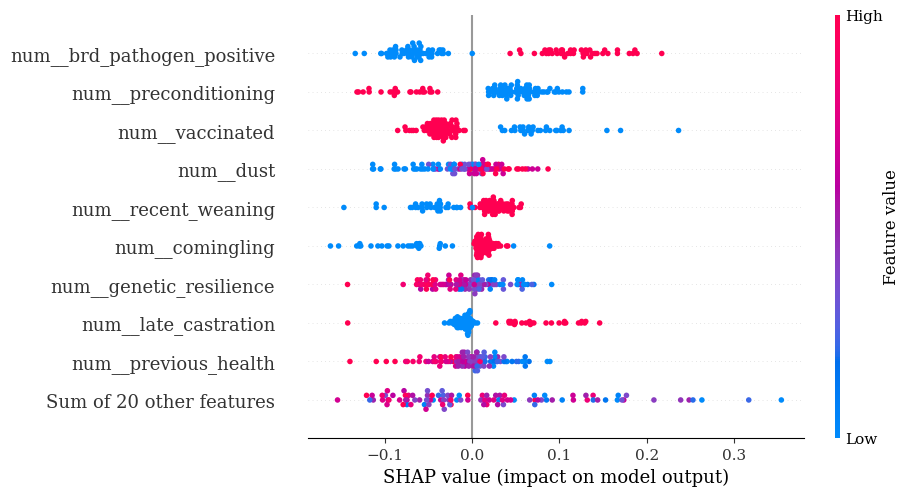

SHAP summary: XGBoost (optimized)


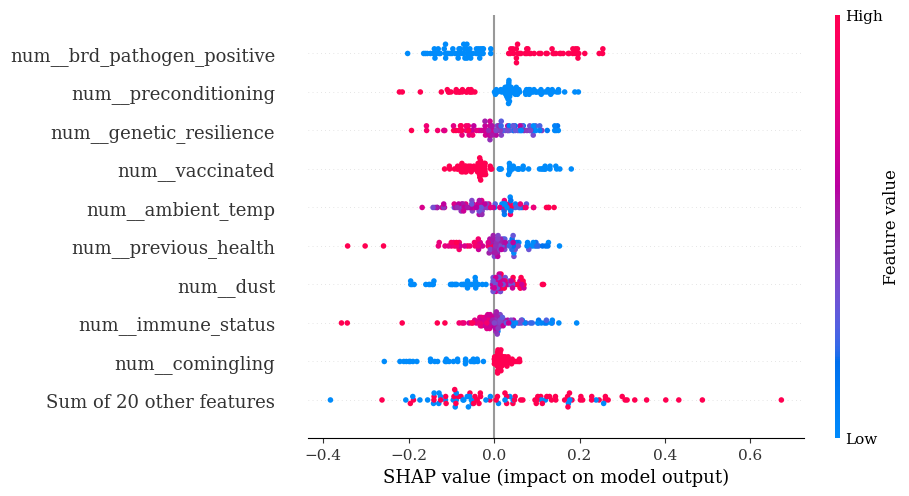

              Model               Feature  MeanAbsSHAP
K-Nearest Neighbors brd_pathogen_positive     0.091586
K-Nearest Neighbors       preconditioning     0.062795
K-Nearest Neighbors            vaccinated     0.051792
K-Nearest Neighbors                  dust     0.035444
K-Nearest Neighbors        recent_weaning     0.035167
K-Nearest Neighbors            comingling     0.035057
K-Nearest Neighbors    genetic_resilience     0.030927
K-Nearest Neighbors       late_castration     0.030610
K-Nearest Neighbors       previous_health     0.029166
K-Nearest Neighbors         immune_status     0.027205
Logistic Regression brd_pathogen_positive     0.103885
Logistic Regression       preconditioning     0.076702
Logistic Regression            vaccinated     0.067431
Logistic Regression    genetic_resilience     0.054736
Logistic Regression       previous_health     0.054569
Logistic Regression                  dust     0.051042
Logistic Regression         immune_status     0.047887
Logistic R

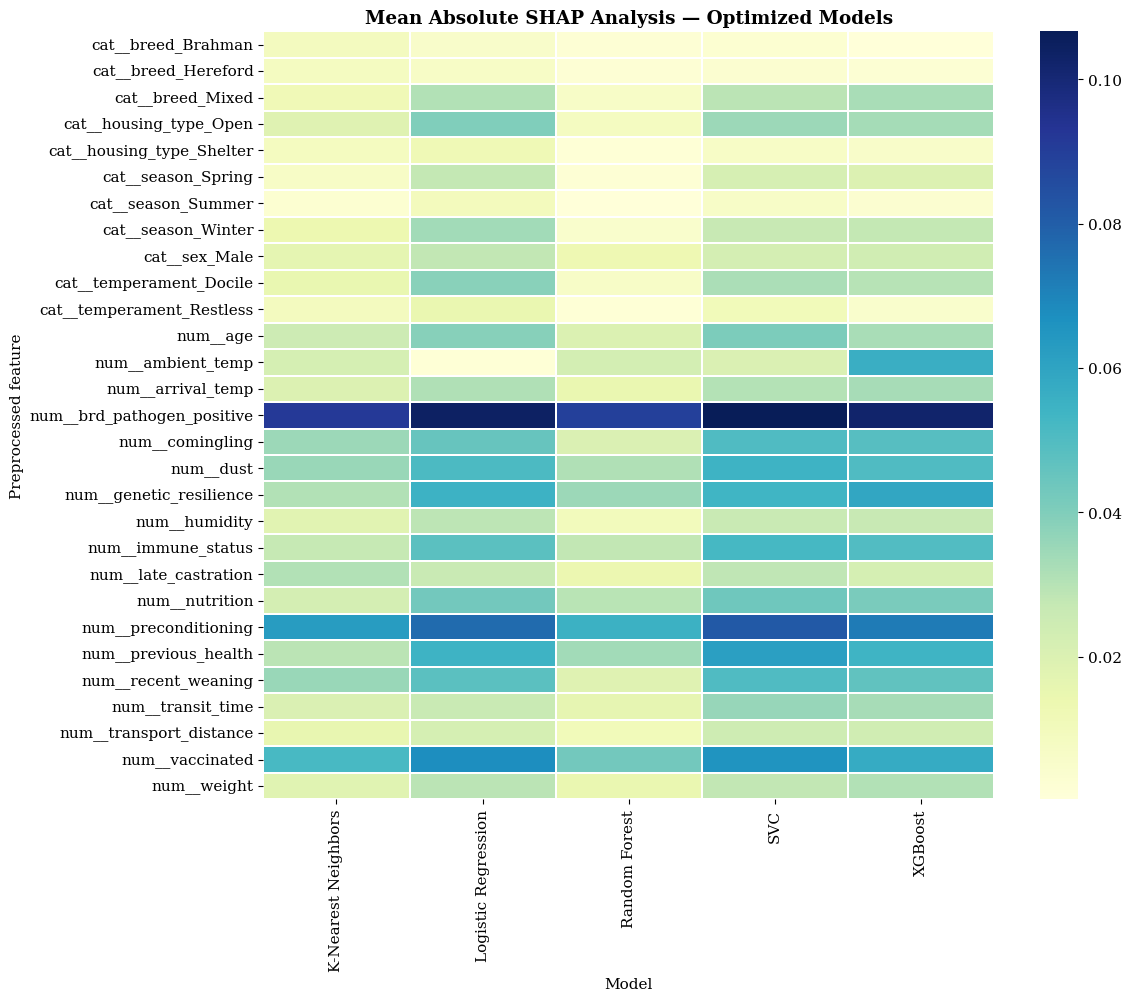

In [27]:
# SHAP analysis using the optimized estimators in optimized_models.
# Explanations target the probability of class 1 (BRD risk).

import shap

shap_background_opt = X_train.sample(
    n=min(50, len(X_train)), random_state=42
)
shap_samples_opt = X_test.sample(
    n=min(100, len(X_test)), random_state=42
)

shap_explanations_opt = {}
shap_importance_rows_opt = []

for model_name, model_info in optimized_models.items():
    optimized_pipeline = model_info["best_estimator"]
    fitted_preprocessor = optimized_pipeline.named_steps["preprocess"]
    classifier = optimized_pipeline.named_steps["clf"]

    background_transformed = fitted_preprocessor.transform(shap_background_opt)
    samples_transformed = fitted_preprocessor.transform(shap_samples_opt)

    if hasattr(background_transformed, "toarray"):
        background_transformed = background_transformed.toarray()
    if hasattr(samples_transformed, "toarray"):
        samples_transformed = samples_transformed.toarray()

    feature_names_opt = fitted_preprocessor.get_feature_names_out()

    def predict_positive_probability(data, clf=classifier):
        return clf.predict_proba(data)[:, 1]

    optimized_explainer = shap.Explainer(
        predict_positive_probability,
        shap.maskers.Independent(background_transformed),
        algorithm="permutation",
        feature_names=feature_names_opt
    )

    explanation_opt = optimized_explainer(
        samples_transformed,
        max_evals=2 * len(feature_names_opt) + 1
    )
    shap_explanations_opt[model_name] = explanation_opt

    mean_abs_shap = np.abs(explanation_opt.values).mean(axis=0)
    shap_importance_rows_opt.extend(
        {
            "Model": model_name,
            "Feature": feature,
            "MeanAbsSHAP": importance
        }
        for feature, importance in zip(feature_names_opt, mean_abs_shap)
    )

    print(f"SHAP summary: {model_name} (optimized)")
    shap.plots.beeswarm(explanation_opt, max_display=10)

shap_importance_df_opt = pd.DataFrame(shap_importance_rows_opt)

# Show the top 10 features for each optimized model.
top_shap_features_opt = (
    shap_importance_df_opt
    .assign(Feature=lambda df: df["Feature"].str.replace(r"^(num|cat)__", "", regex=True))
    .sort_values(["Model", "MeanAbsSHAP"], ascending=[True, False])
    .groupby("Model", sort=False)
    .head(10)
    .reset_index(drop=True)
)
print(top_shap_features_opt.to_string(index=False))

# Compare mean absolute SHAP importance across optimized models.
shap_importance_pivot_opt = shap_importance_df_opt.pivot(
    index="Feature",
    columns="Model",
    values="MeanAbsSHAP"
).fillna(0)

plt.figure(figsize=(12, max(6, 0.35 * len(shap_importance_pivot_opt))))
sns.heatmap(shap_importance_pivot_opt, cmap="YlGnBu", linewidths=0.3)
plt.title("Mean Absolute SHAP Analysis — Optimized Models")
plt.xlabel("Model")
plt.ylabel("Preprocessed feature")
plt.tight_layout()
plt.show()

C:\Users\adeolu.adekunle\AppData\Local\Temp\ipykernel_3684\4118796462.py:25: FutureWarning:

The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.



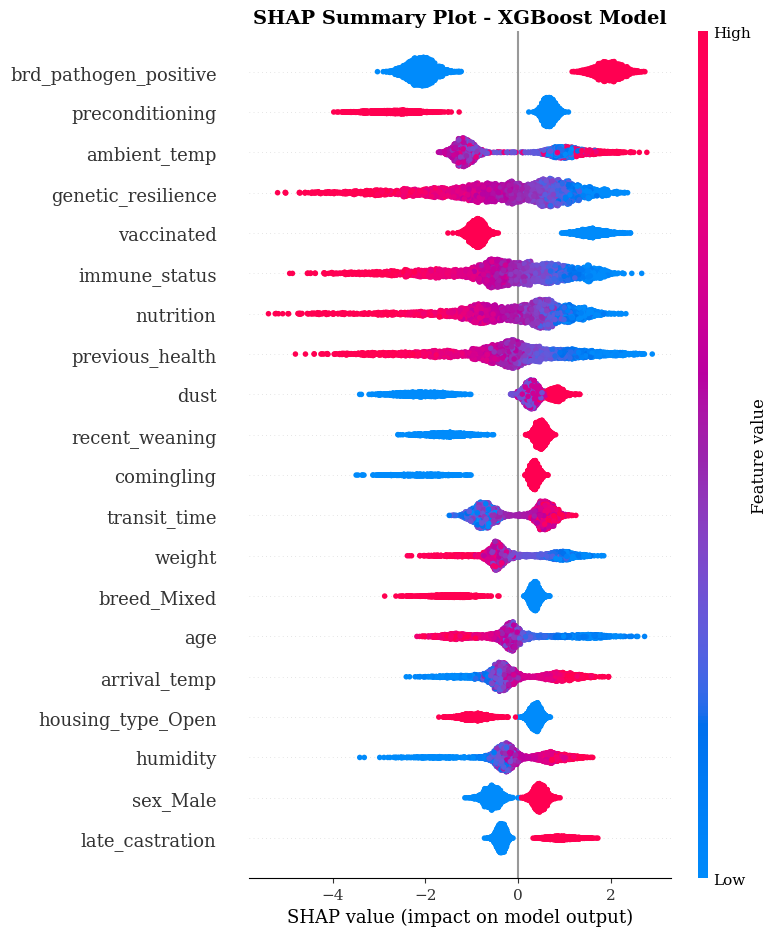

C:\Users\adeolu.adekunle\AppData\Local\Temp\ipykernel_3684\4118796462.py:32: FutureWarning:

The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.



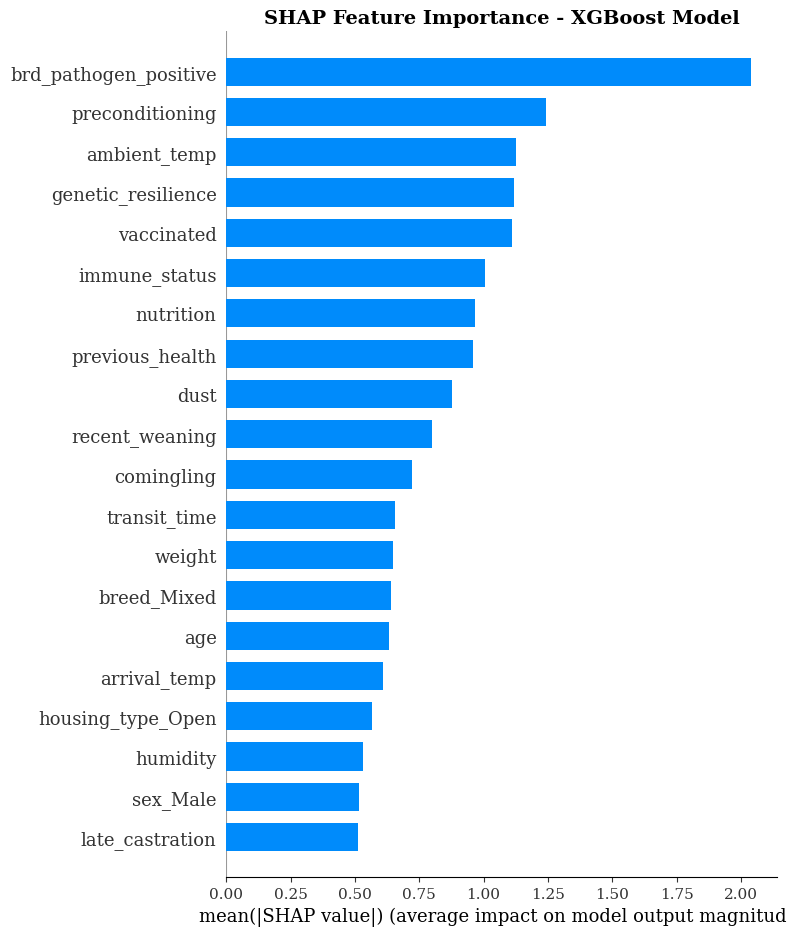

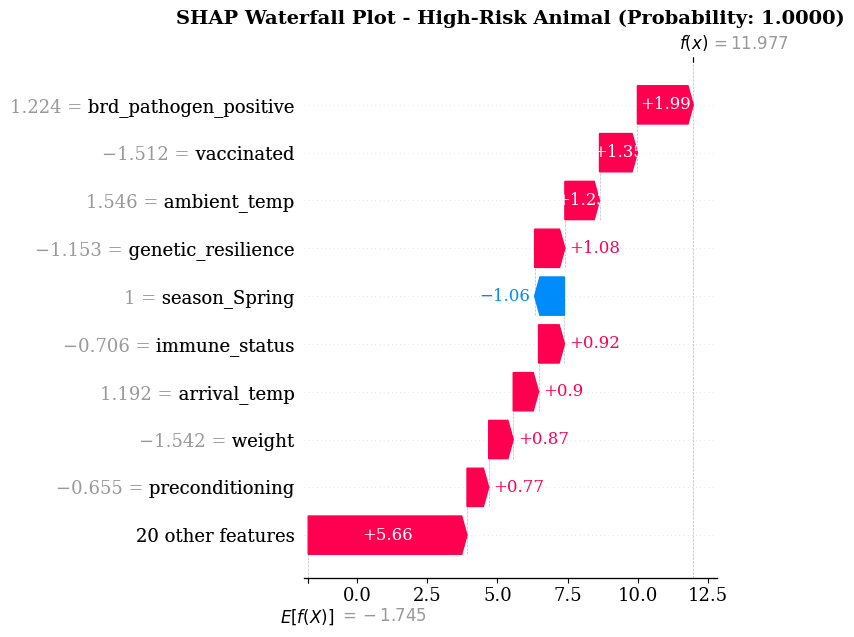

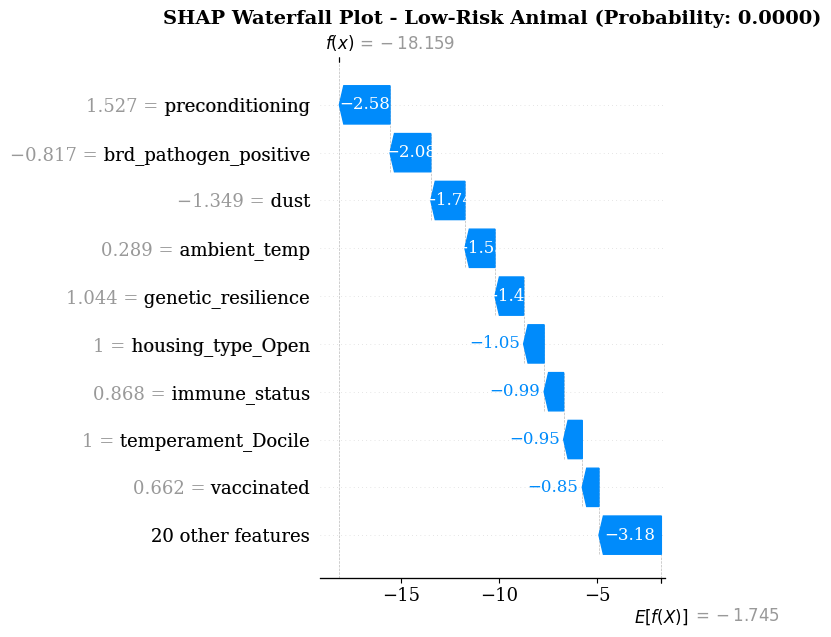

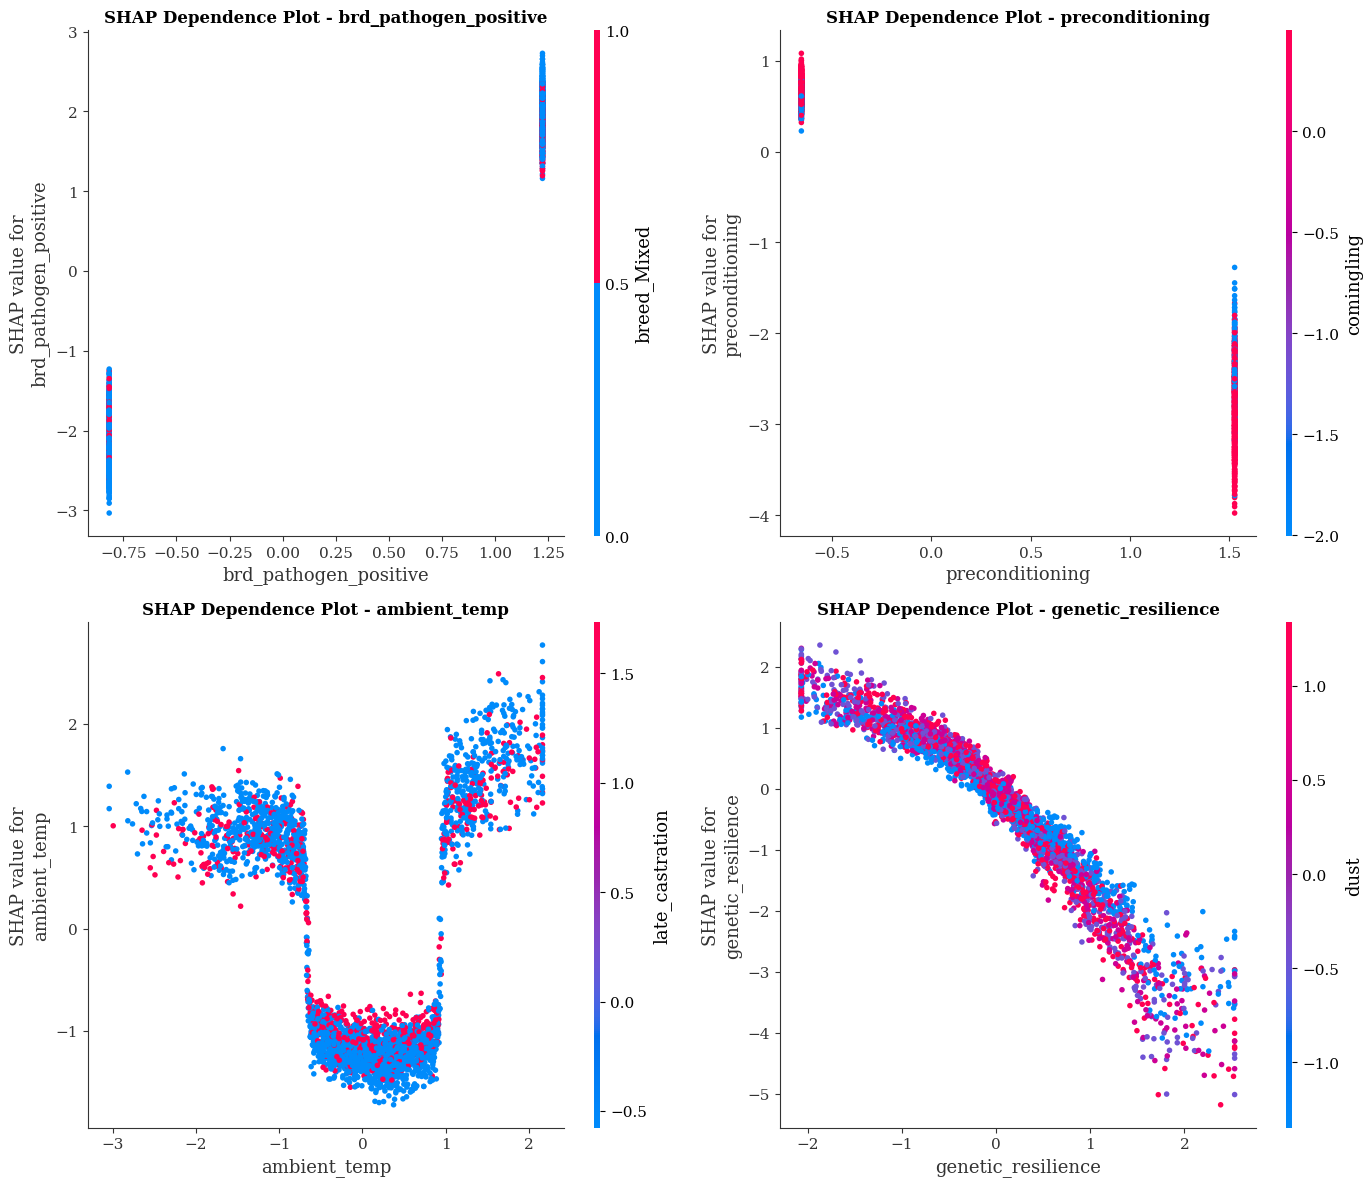

SHAP Analysis Complete!

Expected Model Output (Base Value): -1.7450

Top 5 Features for Dependence Analysis:
  1. brd_pathogen_positive
  2. preconditioning
  3. ambient_temp
  4. genetic_resilience


In [28]:
import shap

# Create SHAP explainer for XGBoost model
# Extract the preprocessed test data
X_test_processed = xgb_pipeline.named_steps["preprocess"].transform(X_test)

# Create explainer using the XGBoost model
xgb_model = xgb_pipeline.named_steps["clf"]
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values for test set
shap_values = explainer.shap_values(X_test_processed)

# Get feature names after preprocessing
if categorical_features:
    ohe = xgb_pipeline.named_steps["preprocess"].named_transformers_["cat"].named_steps["onehot"]
    encoded_cat = ohe.get_feature_names_out(categorical_features)
else:
    encoded_cat = []

feature_names_processed = numeric_features + list(encoded_cat)

# 1. SHAP Summary Plot (Dot Plot)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_processed, feature_names=feature_names_processed, plot_type="dot", show=False)
plt.title("SHAP Summary Plot - XGBoost Model", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# 2. SHAP Summary Plot (Bar Plot)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_processed, feature_names=feature_names_processed, plot_type="bar", show=False)
plt.title("SHAP Feature Importance - XGBoost Model", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# 3. SHAP Waterfall Plot for High-Risk Animal (highest prediction probability)
y_proba_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]
high_risk_idx = np.argmax(y_proba_xgb)

plt.figure(figsize=(10, 8))
shap.waterfall_plot(shap.Explanation(values=shap_values[high_risk_idx], 
                                      base_values=explainer.expected_value,
                                      data=X_test_processed[high_risk_idx],
                                      feature_names=feature_names_processed), 
                     show=False)
plt.title(f"SHAP Waterfall Plot - High-Risk Animal (Probability: {y_proba_xgb[high_risk_idx]:.4f})", 
          fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# 4. SHAP Waterfall Plot for Low-Risk Animal (lowest prediction probability)
low_risk_idx = np.argmin(y_proba_xgb)

plt.figure(figsize=(10, 8))
shap.waterfall_plot(shap.Explanation(values=shap_values[low_risk_idx], 
                                      base_values=explainer.expected_value,
                                      data=X_test_processed[low_risk_idx],
                                      feature_names=feature_names_processed), 
                     show=False)
plt.title(f"SHAP Waterfall Plot - Low-Risk Animal (Probability: {y_proba_xgb[low_risk_idx]:.4f})", 
          fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# 5. SHAP Dependence Plots for Top 5 Features
mean_abs_shap = np.abs(shap_values).mean(axis=0)
top_5_features = [
    feature_names_processed[i]
    for i in np.argsort(mean_abs_shap)[-4:][::-1]
]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for idx, feature in enumerate(top_5_features):
    feature_idx = feature_names_processed.index(feature)
    
    shap.dependence_plot(feature_idx, shap_values, X_test_processed, 
                         feature_names=feature_names_processed, 
                         ax=axes[idx], show=False)
    axes[idx].set_title(f"SHAP Dependence Plot - {feature}", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

print("SHAP Analysis Complete!")
print(f"\nExpected Model Output (Base Value): {explainer.expected_value:.4f}")
print(f"\nTop 5 Features for Dependence Analysis:")
for i, feature in enumerate(top_5_features, 1):
    print(f"  {i}. {feature}")